# PCS26/84 — DEEP LEARNING-BASED FAKE NEWS DETECTION

## Notebook 01 — Dataset Audit and Exploratory Data Analysis

| | |
|---|---|
| **Project code** | PCS26/84 |
| **Project title** | DEEP LEARNING-BASED FAKE NEWS DETECTION |
| **Position in the project** | Notebook 1 of 5 (01 audit/EDA → 02 ML baselines → 03 LSTM/BiLSTM → 04 transformer → 05 evaluation & explainability) |
| **Label convention (all notebooks)** | **Fake = 0, Real = 1** |

### Abstract
This notebook audits the news dataset before any model is trained. It documents provenance, verifies how labels were assigned, quantifies missing and empty text, separates *exact duplicates*, *repeated title/body pairs* and *near-duplicates*, and examines class balance, article and headline length, subject and publication date. It then looks specifically for **publisher and formatting shortcuts** — features that identify *where* a text came from rather than *whether it is true* — and verifies the saved train/validation/test split that every later notebook reuses. The principal conclusion is that the dataset is clean at the schema level but is a **source-confounded benchmark**: all Real articles come from one publisher. High scores on it must not be read as evidence of real-world fact verification.

### Research questions
1. **RQ1 (integrity):** Are the data, labels and split internally consistent and free of conflicting duplicates?
2. **RQ2 (leakage):** Do repeated or near-repeated articles cross the train/validation/test boundary?
3. **RQ3 (shortcuts):** Which publisher, metadata or formatting features separate the classes without describing content?
4. **RQ4 (implications):** What must later notebooks do (input variants, evaluation views, limitations) because of these findings?

### Methodology in one paragraph
Raw files are never modified. Every cleaning step is counted by class. Duplicates are classified by type. The saved split manifest is loaded, never regenerated, and its integrity is *computed* (not asserted). Shortcut analysis uses the **training partition only**. EDA statistics describe the dataset; they **do not prove causation and do not establish that a model will generalise**.

### How to run
Open from the project root or `notebooks/`, select the project `.venv` kernel, **Restart & Run All**. Requires `src/fakenews_utils.py`, `pandas numpy scikit-learn matplotlib seaborn wordcloud`.

In [1]:
from pathlib import Path
import json
import os
import sys
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display

warnings.filterwarnings("default")


def find_project_root(marker="dataset"):
    """Walk upwards from the working directory until a folder containing
    `dataset/` is found (works from the project root or from notebooks/)."""
    here = Path.cwd().resolve()
    for candidate in [here, *here.parents]:
        if (candidate / marker).is_dir():
            return candidate
    raise FileNotFoundError(
        f"No '{marker}/' folder found above {here}. "
        "Open the notebook from the project root or from notebooks/."
    )


PROJECT_ROOT = find_project_root()
DATA_DIR = PROJECT_ROOT / "dataset"
RESULTS_DIR = PROJECT_ROOT / "results"
FIGURES_DIR = RESULTS_DIR / "figures"
TABLES_DIR = RESULTS_DIR / "tables"
SRC_DIR = PROJECT_ROOT / "src"

# Aliases used by the EDA cells below (defined once, here, before any use).
RESULTS_FIGURES = FIGURES_DIR
RESULTS_TABLES = TABLES_DIR

for folder in [FIGURES_DIR, TABLES_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42

# Safety switches. The split manifest already exists and is authoritative.
# It is only ever *created* if it is missing AND this flag is explicitly on.
ALLOW_MANIFEST_CREATION = os.environ.get("FN_ALLOW_MANIFEST_CREATION", "0") == "1"
RECOMPUTE_NEAR_DUPLICATES = False   # set True to redo the (slow) near-duplicate scan

# Shared helpers (preprocessing rules, hashing, protected writes).
sys.path.insert(0, str(SRC_DIR))
if not (SRC_DIR / "fakenews_utils.py").exists():
    raise FileNotFoundError(
        f"{SRC_DIR / 'fakenews_utils.py'} not found. Copy the delivered src/ folder "
        "into the project root (next to dataset/)."
    )
import fakenews_utils as fu

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": 300,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
    "figure.autolayout": True
})

print("Project root:", PROJECT_ROOT)
print("Dataset directory:", DATA_DIR)
print("Results directory:", RESULTS_DIR)
print("Split manifest creation allowed:", ALLOW_MANIFEST_CREATION)
print("Notebook configuration complete.")

Project root: C:\Users\mi\Desktop\Fake-news detection
Dataset directory: C:\Users\mi\Desktop\Fake-news detection\dataset
Results directory: C:\Users\mi\Desktop\Fake-news detection\results
Split manifest creation allowed: False
Notebook configuration complete.


In [2]:

required_files = [
    DATA_DIR / "Fake.csv",
    DATA_DIR / "True.csv",
    DATA_DIR / "combined_fake_news.csv"
]

file_report = pd.DataFrame([
    {
        "File": path.name,
        "Exists": path.exists(),
        "Size_MB": round(path.stat().st_size / (1024 ** 2), 2)
        if path.exists() else None
    }
    for path in required_files
])

display(file_report)

missing_files = [
    str(path) for path in required_files
    if not path.exists()
]

if missing_files:
    raise FileNotFoundError(
        "Required dataset file(s) missing:\n"
        + "\n".join(missing_files)
    )

,File,Exists,Size_MB
0,Fake.csv,True,59.88
1,True.csv,True,51.10
2,combined_fake_news.csv,True,111.07


In [3]:

DATA_PATH = DATA_DIR / "combined_fake_news.csv"

df = pd.read_csv(DATA_PATH, low_memory=False)

# Standardize accidental whitespace in column names.
df.columns = df.columns.str.strip()

required_columns = {"title", "text", "subject", "date", "label"}
missing_columns = required_columns - set(df.columns)

if missing_columns:
    raise ValueError(
        f"Dataset is missing required columns: {sorted(missing_columns)}"
    )

print("Dataset loaded successfully.")
print(f"Shape: {df.shape[0]:,} rows × {df.shape[1]} columns")
print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
display(df.dtypes.rename("dtype").to_frame())

print("\nSample records:")
display(df.head(5))

Dataset loaded successfully.
Shape: 44,898 rows × 5 columns

Column names:
['title', 'text', 'subject', 'date', 'label']

Data types:


,dtype
title,str
text,str
subject,str
date,str
label,int64



Sample records:


,title,text,subject,date,label
0,Ben Stein Calls Out 9th Circuit Court: Committ...,"21st Century Wire says Ben Stein, reputable pr...",US_News,"February 13, 2017",0
1,Trump drops Steve Bannon from National Securit...,WASHINGTON (Reuters) - U.S. President Donald T...,politicsNews,"April 5, 2017",1
2,Puerto Rico expects U.S. to lift Jones Act shi...,(Reuters) - Puerto Rico Governor Ricardo Rosse...,politicsNews,"September 27, 2017",1
3,OOPS: Trump Just Accidentally Confirmed He Le...,"On Monday, Donald Trump once again embarrassed...",News,"May 22, 2017",0
4,Donald Trump heads for Scotland to reopen a go...,"GLASGOW, Scotland (Reuters) - Most U.S. presid...",politicsNews,"June 24, 2016",1


### Dataset structure
The combined file has five columns: `title` (headline), `text` (article body), `subject` (the news section under which the article was listed), `date` (publication date, stored as text) and `label` (0 = Fake, 1 = Real). `subject` and `date` are **metadata**, not article content. They are analysed here but are **never given to any predictive model** in this project, because (as shown below) they are almost perfect proxies for the label.

## Dataset provenance, citation and label assignment

**What the files are.** `Fake.csv` / `True.csv` with the columns `title, text, subject, date`, and the combined file of 44,898 rows (23,481 Fake / 21,417 Real — original Notebook 01 output), match the structure and published class counts of the **ISOT Fake News Dataset** (University of Victoria). The notebooks cannot prove which download these files came from, so this match is *consistent evidence*, not proof; please also record the URL/date you downloaded them from.

**How the data was collected (as described in the secondary literature).** Real articles were crawled from Reuters.com; fake articles come from websites flagged by PolitiFact and Wikipedia. Consequently *all* Real articles share one publisher, while Fake articles come from many — a source confound that this project must treat as a limitation (see the marker analysis below). A 2023 paper that uses this dataset reports the same problem, noting that body texts beginning with the Reuters dateline were always real, and removes source information before modelling (arXiv:2305.19194, *FakeSwarm: Improving Fake News Detection with Swarming Characteristics*; author list not retrieved in this check).

**Citation (checked 11 Oct 2026).**
* Ahmed, H., Traore, I., & Saad, S. (2017). *Detection of Online Fake News Using N-Gram Analysis and Machine Learning Techniques.* Lecture Notes in Computer Science, pp. 127–138. https://doi.org/10.1007/978-3-319-69155-8_9
* Ahmed, H., Traore, I., & Saad, S. (2018). *Detecting opinion spams and fake news using text classification.* Security and Privacy, 1(1), Wiley. https://doi.org/10.1002/spy2.9

**Verification status.** The bibliographic details above were confirmed from secondary records (a Mendeley Data record, DOI 10.17632/945z9xkc8d.1, quoting the first citation; Zendy and Labelbox records for the second). The publisher pages themselves could not be opened during this check (rate-limited), so **complete the volume/editor/publisher fields from the publisher page before submitting the report.**

**Label assignment.** The cell that built `combined_fake_news.csv` is not in any notebook, so the label rule (`Fake.csv → 0`, `True.csv → 1`) was previously undocumented. The next cell verifies it empirically against the raw files instead of assuming it.

In [4]:
# Verify how labels were assigned in combined_fake_news.csv by tracing every
# combined row back to Fake.csv / True.csv (normalised title+body key).
raw_fake = pd.read_csv(DATA_DIR / "Fake.csv", low_memory=False)
raw_true = pd.read_csv(DATA_DIR / "True.csv", low_memory=False)
for frame in (raw_fake, raw_true):
    frame.columns = frame.columns.str.strip()

fake_keys = set(fu.article_key(raw_fake["title"], raw_fake["text"]))
true_keys = set(fu.article_key(raw_true["title"], raw_true["text"]))
combined_keys = fu.article_key(df["title"], df["text"])

in_fake = combined_keys.isin(fake_keys)
in_true = combined_keys.isin(true_keys)

expected_label = pd.Series(
    np.where(in_fake & ~in_true, 0, np.where(in_true & ~in_fake, 1, -1)),
    index=df.index,
)
traceable = expected_label.isin([0, 1])
mismatch = traceable & (expected_label != df["label"])

subjects_fake = set(raw_fake["subject"].dropna().unique())
subjects_true = set(raw_true["subject"].dropna().unique())

label_verification = pd.DataFrame({
    "Check": [
        "Rows in Fake.csv",
        "Rows in True.csv",
        "Rows in combined_fake_news.csv",
        "Combined rows traced only to Fake.csv",
        "Combined rows traced only to True.csv",
        "Combined rows found in BOTH raw files (ambiguous)",
        "Combined rows found in NEITHER raw file",
        "Traceable rows whose label disagrees with the source file",
        "Subjects shared by Fake.csv and True.csv",
    ],
    "Value": [
        len(raw_fake), len(raw_true), len(df),
        int((in_fake & ~in_true).sum()), int((in_true & ~in_fake).sum()),
        int((in_fake & in_true).sum()), int((~in_fake & ~in_true).sum()),
        int(mismatch.sum()), len(subjects_fake & subjects_true),
    ],
})
display(label_verification)
label_verification.to_csv(TABLES_DIR / "label_assignment_verification.csv", index=False)

if int(mismatch.sum()) == 0 and int((~in_fake & ~in_true).sum()) == 0:
    print("Label assignment verified: every combined row traces to its source file "
          "and carries the expected label (Fake.csv -> 0, True.csv -> 1).")
else:
    print("WARNING: label assignment could not be fully verified - inspect the table above "
          "before using the labels.")
print("Note: this verifies the combination step only; it cannot validate the original "
      "labelling by the dataset authors.")

,Check,Value
0,Rows in Fake.csv,23481
1,Rows in True.csv,21417
2,Rows in combined_fake_news.csv,44898
3,Combined rows traced only to Fake.csv,23481
4,Combined rows traced only to True.csv,21417
5,Combined rows found in BOTH raw files (ambiguous),0
6,Combined rows found in NEITHER raw file,0
7,Traceable rows whose label disagrees with the ...,0
8,Subjects shared by Fake.csv and True.csv,0


Label assignment verified: every combined row traces to its source file and carries the expected label (Fake.csv -> 0, True.csv -> 1).
Note: this verifies the combination step only; it cannot validate the original labelling by the dataset authors.


**Interpretation (label verification).** All 23,481 rows of `Fake.csv` and all 21,417 rows of `True.csv` are found in the combined file with the expected label (Fake.csv → 0, True.csv → 1); no row is ambiguous, untraceable or mislabelled, and the two raw files share no `subject` value. **Verified fact:** the combination step is correct. **Not verified:** the original labelling by the dataset authors — the project inherits their labels and assumptions.

In [5]:

import pandas as pd

# Use the original combined dataset for quality auditing
audit_df = pd.read_csv(
    PROJECT_ROOT / "dataset" / "combined_fake_news.csv"
)

# Calculate dataset quality metrics
quality_report = pd.DataFrame({
    "Metric": [
        "Total records",
        "Total columns",
        "Missing cells",
        "Rows with missing text",
        "Rows with empty/whitespace-only text",
        "Rows with empty/whitespace-only titles",
        "Exact duplicate rows",
        "Unique labels"
    ],
    "Value": [
        len(audit_df),
        len(audit_df.columns),
        int(audit_df.isna().sum().sum()),
        int(audit_df["text"].isna().sum()),
        int(
            audit_df["text"]
            .fillna("")
            .astype(str)
            .str.strip()
            .eq("")
            .sum()
        ),
        int(
            audit_df["title"]
            .fillna("")
            .astype(str)
            .str.strip()
            .eq("")
            .sum()
        ),
        int(audit_df.duplicated().sum()),
        int(audit_df["label"].nunique())
    ]
})

display(quality_report)

# Save the report
quality_report.to_csv(
    RESULTS_TABLES / "dataset_quality_report.csv",
    index=False
)

print("Dataset quality report generated successfully.")
print("Saved to:", RESULTS_TABLES / "dataset_quality_report.csv")

,Metric,Value
0,Total records,44898
1,Total columns,5
2,Missing cells,0
3,Rows with missing text,0
4,Rows with empty/whitespace-only text,631
5,Rows with empty/whitespace-only titles,0
6,Exact duplicate rows,209
7,Unique labels,2


Dataset quality report generated successfully.
Saved to: C:\Users\mi\Desktop\Fake-news detection\results\tables\dataset_quality_report.csv


,label,class,records,percentage
0,0,Fake,23481,52.3
1,1,Real,21417,47.7


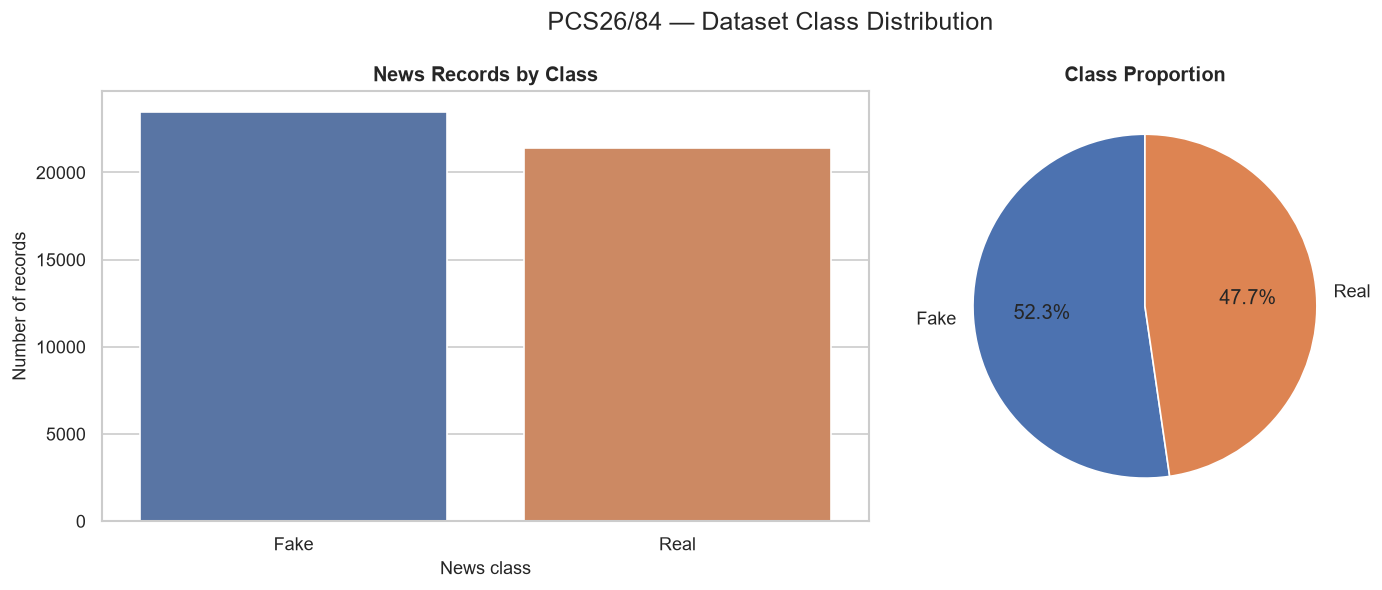

In [6]:

# Confirm the project's label convention.
LABEL_MAP = {0: "Fake", 1: "Real"}

unexpected_labels = set(df["label"].dropna().unique()) - set(LABEL_MAP)

if unexpected_labels:
    raise ValueError(f"Unexpected label values: {unexpected_labels}")

label_summary = (
    df["label"]
    .value_counts()
    .rename_axis("label")
    .rename("records")
    .reset_index()
)

label_summary["class"] = label_summary["label"].map(LABEL_MAP)
label_summary["percentage"] = (
    label_summary["records"] / len(df) * 100
).round(2)

label_summary = label_summary[
    ["label", "class", "records", "percentage"]
]

display(label_summary)

label_summary.to_csv(
    TABLES_DIR / "class_distribution.csv", index=False
)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.barplot(
    data=label_summary,
    x="class",
    y="records",
    hue="class",
    legend=False,
    ax=axes[0]
)
axes[0].set_title("News Records by Class")
axes[0].set_xlabel("News class")
axes[0].set_ylabel("Number of records")

axes[1].pie(
    label_summary["records"],
    labels=label_summary["class"],
    autopct="%1.1f%%",
    startangle=90
)
axes[1].set_title("Class Proportion")

fig.suptitle("PCS26/84 — Dataset Class Distribution", fontsize=15)
fig.savefig(FIGURES_DIR / "01_class_distribution.png", bbox_inches="tight")
plt.show()

**Interpretation (raw class balance).** The raw data hold 23,481 Fake (52.3 %) and 21,417 Real (47.7 %) articles — a mild imbalance. Accuracy is therefore not misleading by itself, but later notebooks still report per-class precision/recall and **macro-F1** so that a weakness on one class cannot hide behind the overall score.

In [7]:
# Never overwrite df or the original CSV.
df_work = df.copy()

initial_rows = len(df_work)

# Remove records with missing or whitespace-only news text.
text_is_valid = (
    df_work["text"].notna()
    & df_work["text"].astype("string").str.strip().ne("").fillna(False)
)

df_nonempty = df_work.loc[text_is_valid].copy()
empty_text_removed = initial_rows - len(df_nonempty)

# Remove exact duplicate records after filtering empty text.
df_clean = df_nonempty.drop_duplicates().copy()
exact_duplicates_removed = len(df_nonempty) - len(df_clean)

df_clean["label"] = df_clean["label"].astype("int64")
df_clean = df_clean.reset_index(drop=True)

cleaning_audit = pd.DataFrame([
    {"stage": "Original combined dataset", "records": initial_rows},
    {"stage": "After removing empty news text", "records": len(df_nonempty)},
    {"stage": "After removing exact duplicate rows", "records": len(df_clean)}
])

display(cleaning_audit)

print(f"Empty-text records removed: {empty_text_removed:,}")
print(f"Exact duplicate records removed: {exact_duplicates_removed:,}")
print(f"Final analysis dataset: {len(df_clean):,} records")
print("\nClass counts after cleaning:")
display(
    df_clean["label"].map(LABEL_MAP)
    .value_counts()
    .rename_axis("class")
    .to_frame("records")
)

cleaning_audit.to_csv(
    TABLES_DIR / "data_cleaning_audit.csv", index=False
)

# PROTECTED WRITE: the cleaned CSV is referenced by the split manifest (row positions).
# It is written only if absent; if it already exists and is identical nothing is
# rewritten; if it differs, the new version is saved as *.REBUILT.csv instead.
clean_csv_status = fu.write_protected_csv(
    df_clean, DATA_DIR / "combined_fake_news_clean.csv"
)
print("Clean dataset file:", clean_csv_status)

assert df_clean["text"].notna().all()
assert df_clean["text"].astype("string").str.strip().ne("").all()
assert not df_clean.duplicated().any()

,stage,records
0,Original combined dataset,44898
1,After removing empty news text,44267
2,After removing exact duplicate rows,44058


Empty-text records removed: 631
Exact duplicate records removed: 209
Final analysis dataset: 44,058 records

Class counts after cleaning:


,records
class,
Fake,22848
Real,21210


Clean dataset file: identical (not rewritten)


**Summary (cleaning decisions).** Two rule-based exclusions were applied: (1) records with empty or whitespace-only body text, (2) rows that are *exact* duplicates across all five columns. The raw file is untouched; the cleaned file is written once and protected from overwriting. Cleaning is a **methodological choice, not an automatic improvement** — Notebook 02 tests how much the choice matters.

### Exclusions by class
The cleaning step removes records in two stages. The table below reports the *calculated* number removed per class at each stage, because a class-skewed exclusion would itself be a dataset shortcut.

In [8]:
def counts_by_class(frame):
    return (
        frame["label"].map(LABEL_MAP).value_counts()
        .reindex(["Fake", "Real"], fill_value=0)
    )

stages = [
    ("Original combined dataset", df_work),
    ("After removing empty news text", df_nonempty),
    ("After removing exact duplicate rows", df_clean),
]
stage_rows = []
for stage_name, frame in stages:
    c = counts_by_class(frame)
    stage_rows.append({"stage": stage_name, "Fake": int(c["Fake"]),
                       "Real": int(c["Real"]), "Total": len(frame)})
stage_table = pd.DataFrame(stage_rows)

c0, c1, c2 = (counts_by_class(f) for _, f in stages)
exclusion_table = pd.DataFrame({
    "exclusion": ["Empty / whitespace-only text (title-only records)",
                  "Exact duplicate rows (all 5 columns identical)",
                  "Total removed"],
    "Fake removed": [int(c0["Fake"] - c1["Fake"]), int(c1["Fake"] - c2["Fake"]),
                     int(c0["Fake"] - c2["Fake"])],
    "Real removed": [int(c0["Real"] - c1["Real"]), int(c1["Real"] - c2["Real"]),
                     int(c0["Real"] - c2["Real"])],
})
exclusion_table["Fake removed (% of Fake)"] = (exclusion_table["Fake removed"] / c0["Fake"] * 100).round(2)
exclusion_table["Real removed (% of Real)"] = (exclusion_table["Real removed"] / c0["Real"] * 100).round(2)

display(stage_table)
display(exclusion_table)

stage_table.to_csv(TABLES_DIR / "exclusions_by_class_stages.csv", index=False)
exclusion_table.to_csv(TABLES_DIR / "exclusions_by_class.csv", index=False)

,stage,Fake,Real,Total
0,Original combined dataset,23481,21417,44898
1,After removing empty news text,22851,21416,44267
2,After removing exact duplicate rows,22848,21210,44058


,exclusion,Fake removed,Real removed,Fake removed (% of Fake),Real removed (% of Real)
0,Empty / whitespace-only text (title-only records),630,1,2.68,0.00
1,Exact duplicate rows (all 5 columns identical),3,206,0.01,0.96
2,Total removed,633,207,2.70,0.97


**Interpretation (exclusions by class).** Of 631 empty-text records, **630 are Fake and 1 is Real**; the 209 exact duplicates are almost all Real (206 Real, 3 Fake). Empty bodies are therefore a near-perfect *Fake-only* artefact of the collection process, not random noise. Removing them is reasonable for a *content* classifier, but it also means the models never see — and cannot be claimed to handle — headline-only input.

### Title-only records (empty body)
Records whose body is empty or whitespace-only contain nothing but a title. They are **removed** from all models in this project, so no model is ever evaluated on title-only input. The next cell characterises them; if they are strongly concentrated in one class they would have been a shortcut, and the report must say that deployment on headline-only input is out of scope.

In [9]:
title_only = df_work.loc[~text_is_valid].copy()
title_only["class"] = title_only["label"].map(LABEL_MAP)

per_class_total = counts_by_class(df_work)
title_only_summary = (
    title_only["class"].value_counts().reindex(["Fake", "Real"], fill_value=0)
    .rename("title_only_records").to_frame()
)
title_only_summary["class_total_in_raw_data"] = per_class_total
title_only_summary["share_of_class_pct"] = (
    title_only_summary["title_only_records"] / title_only_summary["class_total_in_raw_data"] * 100
).round(2)
display(title_only_summary)

print("\nTitle-only records by subject and class:")
display(pd.crosstab(title_only["subject"], title_only["class"]))

# Do these headlines also occur on articles that DO have a body?
retained_titles = set(df_clean["title"].fillna("").astype(str).str.strip().str.lower())
title_only_norm = title_only["title"].fillna("").astype(str).str.strip().str.lower()
print("\nTitle-only headlines that also appear on a retained article:",
      int(title_only_norm.isin(retained_titles).sum()), "of", len(title_only))

# Headline length: title-only records vs retained records of the same class.
title_only["title_words"] = title_only["title"].fillna("").astype(str).str.split().str.len()
retained_words = df_clean.assign(
    title_words=df_clean["title"].fillna("").astype(str).str.split().str.len(),
    **{"class": df_clean["label"].map(LABEL_MAP)},
)
cmp_title = pd.concat([
    title_only.groupby("class")["title_words"].describe()[["count", "mean", "50%"]].assign(group="title-only"),
    retained_words.groupby("class")["title_words"].describe()[["count", "mean", "50%"]].assign(group="retained"),
]).round(2)
display(cmp_title)

print("\nSample title-only headlines (seeded):")
display(title_only.sample(min(10, len(title_only)), random_state=RANDOM_STATE)[["title", "subject", "class"]])

# Very short bodies that survive cleaning.
body_words = df_clean["text"].astype(str).str.split().str.len()
short_rows = []
for limit in (10, 20, 50):
    mask = body_words < limit
    c = counts_by_class(df_clean.loc[mask])
    short_rows.append({"body_words_below": limit, "Fake": int(c["Fake"]), "Real": int(c["Real"])})
short_body_table = pd.DataFrame(short_rows)
print("\nVery short bodies that were kept:")
display(short_body_table)

title_only_summary.to_csv(TABLES_DIR / "title_only_records_summary.csv")
short_body_table.to_csv(TABLES_DIR / "short_body_counts_by_class.csv", index=False)

,title_only_records,class_total_in_raw_data,share_of_class_pct
class,,,
Fake,630,23481,2.68
Real,1,21417,0.00



Title-only records by subject and class:


class,Fake,Real
subject,,
Government News,72,0
left-news,150,0
politics,408,0
politicsNews,0,1



Title-only headlines that also appear on a retained article: 0 of 631


,count,mean,50%,group
class,,,,
Fake,630.0,14.70,14.0,title-only
Real,1.0,4.00,4.0,title-only
Fake,22848.0,14.73,14.0,retained
Real,21210.0,9.95,10.0,retained



Sample title-only headlines (seeded):


,title,subject,class
36557,TWEET OF THE DAY: Hillary…The Price Of Failure,politics,Fake
18240,‘NAFTA BOY’ BILL CLINTON HECKLED At Detroit La...,politics,Fake
15259,WATCH: Widow of Slain Navy SEAL William Ryan O...,politics,Fake
10505,OBAMA’S COMMUNIST CRONY Van Jones Worries Abou...,politics,Fake
35927,(VIDEO) MARK STEYN ON ‘AMERICAN RELEVANCE’ IN ...,Government News,Fake
16498,LOL! HIGH SCHOOL STUDENTS Skip School To Prote...,politics,Fake
11738,WOW! TUCKER CARLSON TAKES ON OBAMACARE ARCHITE...,Government News,Fake
5904,BOOM! The Truth About “FAKE NEWS” Websites: “T...,left-news,Fake
37927,CLUELESS? NEVADA POLL WORKERS BREAK THE LAW We...,politics,Fake
11633,UNDERCOVER JOURNALIST In Burka Is Offered Huma...,left-news,Fake



Very short bodies that were kept:


,body_words_below,Fake,Real
0,10,236,0
1,20,500,0
2,50,1265,322


**Interpretation (title-only and very short records).** Title-only records come overwhelmingly from three Fake subjects, none of their headlines reappears on a retained article, and very short bodies behave the same way: bodies under 20 words are 500 Fake and **0 Real** (the shortest Real body has 22 words). Short length is thus another collection-process shortcut. **Implication:** deployment on headline-only or very short inputs is out of scope and the prediction function must warn about it.

In [10]:

# Normalize only for duplicate auditing; preserve original text for modelling.
audit_df = df_clean.copy()

audit_df["_title_norm"] = (
    audit_df["title"].fillna("").astype(str)
    .str.strip().str.lower()
)
audit_df["_text_norm"] = (
    audit_df["text"].fillna("").astype(str)
    .str.strip().str.lower()
)

audit_df["_article_key"] = (
    audit_df["_title_norm"] + "\n" + audit_df["_text_norm"]
)

article_label_counts = (
    audit_df.groupby("_article_key")["label"].nunique()
)

article_frequency = audit_df["_article_key"].value_counts()

repeated_keys = article_frequency[article_frequency > 1]

duplicate_audit = pd.DataFrame({
    "Metric": [
        "Clean records",
        "Unique normalized title-text pairs",
        "Title-text pairs appearing more than once",
        "Records belonging to repeated title-text pairs",
        "Repeated records beyond one copy per pair",
        "Title-text pairs with conflicting labels"
    ],
    "Value": [
        len(audit_df),
        audit_df["_article_key"].nunique(),
        len(repeated_keys),
        int(article_frequency[
            article_frequency.index.isin(repeated_keys.index)
        ].sum()),
        int((repeated_keys - 1).sum()),
        int((article_label_counts > 1).sum())
    ]
})

display(duplicate_audit)

duplicate_audit.to_csv(
    TABLES_DIR / "duplicate_leakage_audit.csv", index=False
)

# Save a reviewable list of repeated articles, without changing the dataset.
repeated_article_report = (
    audit_df[audit_df["_article_key"].isin(repeated_keys.index)]
    [["title", "subject", "date", "label", "_article_key"]]
    .drop_duplicates()
    .drop(columns="_article_key")
)

repeated_article_report.to_csv(
    TABLES_DIR / "repeated_articles_review.csv", index=False
)

print("Duplicate audit saved.")
print("We will use article groups when creating the model split.")

,Metric,Value
0,Clean records,44058
1,Unique normalized title-text pairs,38656
2,Title-text pairs appearing more than once,4943
3,Records belonging to repeated title-text pairs,10345
4,Repeated records beyond one copy per pair,5402
5,Title-text pairs with conflicting labels,0


Duplicate audit saved.
We will use article groups when creating the model split.


**Interpretation (repeated-pair audit).** After exact duplicates were removed, 4,943 normalised title+body pairs still occur more than once (10,345 records, 5,402 surplus copies) and **none has conflicting labels**. These repeats are not noise to be deleted blindly: they are the same article listed under different `subject` values (4,939 of the 4,943 pairs differ in subject). They must be kept *together* when splitting.

### Duplicate taxonomy
"Duplicate" covers four different things; each needs a different treatment:

| Level | Definition | Treatment in this project |
|---|---|---|
| L1 exact duplicate | all five columns identical | **removed** (cleaning cell) |
| L2 repeated title+body pair | same normalised title and body, but different `subject`/`date` | **kept, but grouped** so a pair never crosses train/validation/test |
| L3 same body, different title | identical normalised body, different headline | *not* grouped by the original split → checked for cross-partition leakage below |
| L4 same title, different body | identical normalised headline, different body | *not* grouped → checked below |
| L5 near-duplicate | highly similar but not identical text | measured against the training set below |

In [11]:
tax = pd.DataFrame({
    "title_norm": df_clean["title"].fillna("").astype(str).str.strip().str.lower(),
    "body_norm": df_clean["text"].fillna("").astype(str).str.strip().str.lower(),
    "subject": df_clean["subject"], "date": df_clean["date"], "label": df_clean["label"],
})
tax["pair_key"] = tax["title_norm"] + fu.GROUP_SEPARATOR + tax["body_norm"]

# L2: repeated normalised title+body pairs
pair_counts = tax["pair_key"].value_counts()
rep_pairs = pair_counts[pair_counts > 1]
rep_rows = tax[tax["pair_key"].isin(rep_pairs.index)]
pair_meta = rep_rows.groupby("pair_key").agg(
    n_subjects=("subject", "nunique"), n_dates=("date", "nunique"))

# L3: same body, different titles
body_grp = tax.groupby("body_norm").agg(
    n=("title_norm", "size"), n_titles=("title_norm", "nunique"), n_labels=("label", "nunique"))
l3 = body_grp[body_grp["n_titles"] > 1]

# L4: same title, different bodies
title_grp = tax.groupby("title_norm").agg(
    n=("body_norm", "size"), n_bodies=("body_norm", "nunique"), n_labels=("label", "nunique"))
l4 = title_grp[title_grp["n_bodies"] > 1]

duplicate_taxonomy = pd.DataFrame([
    {"level": "L1 exact duplicate rows removed", "groups": np.nan,
     "records_affected": exact_duplicates_removed,
     "detail": "removed in the cleaning cell"},
    {"level": "L2 repeated title+body pairs", "groups": len(rep_pairs),
     "records_affected": int(rep_pairs.sum()),
     "detail": f"{int((rep_pairs - 1).sum())} extra copies; "
               f"{int((pair_meta.n_subjects > 1).sum())} pairs differ in subject, "
               f"{int((pair_meta.n_dates > 1).sum())} differ in date; "
               f"{int((tax.groupby('pair_key')['label'].nunique() > 1).sum())} with conflicting labels"},
    {"level": "L3 same body, different title", "groups": len(l3),
     "records_affected": int(l3["n"].sum()),
     "detail": f"{int((l3.n_labels > 1).sum())} groups with conflicting labels"},
    {"level": "L4 same title, different body", "groups": len(l4),
     "records_affected": int(l4["n"].sum()),
     "detail": f"{int((l4.n_labels > 1).sum())} groups with conflicting labels"},
])
display(duplicate_taxonomy)
duplicate_taxonomy.to_csv(TABLES_DIR / "duplicate_taxonomy.csv", index=False)
print("L5 (near-duplicates) is measured after the split, in the near-duplicate section.")

,level,groups,records_affected,detail
0,L1 exact duplicate rows removed,NaN,209,removed in the cleaning cell
1,L2 repeated title+body pairs,4943.0,10345,5402 extra copies; 4939 pairs differ in subjec...
2,"L3 same body, different title",17.0,50,0 groups with conflicting labels
3,"L4 same title, different body",341.0,725,0 groups with conflicting labels


L5 (near-duplicates) is measured after the split, in the near-duplicate section.


**Interpretation (duplicate taxonomy).** The four levels behave differently: exact duplicates were removed; repeated title+body pairs are kept and grouped; 17 body-groups share a body under different headlines and 341 title-groups share a headline over different bodies; **no group at any level has conflicting labels**. Levels L3 and L4 are *not* covered by the pair-level grouping used for the split — the next section measures whether they cross partitions.

text_characters                                       text_words  \
                count     mean  median      std  min    max      count   
class                                                                    
Fake            22848  2617.77  2200.0  2531.65    5  51794      22848   
Real            21210  2378.15  2216.0  1684.43  152  29781      21210   

                                       title_words                              
         mean median     std min   max       count   mean median   std min max  
class                                                                           
Fake   434.89  369.0  407.82   1  8135       22848  14.73   14.0  4.33   1  42  
Real   384.78  359.0  273.90  22  5172       21210   9.95   10.0  1.70   4  20

c:\Users\mi\Desktop\Fake-news detection\.venv\Lib\site-packages\seaborn\categorical.py:700: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)
c:\Users\mi\Desktop\Fake-news detection\.venv\Lib\site-packages\seaborn\categorical.py:700: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)


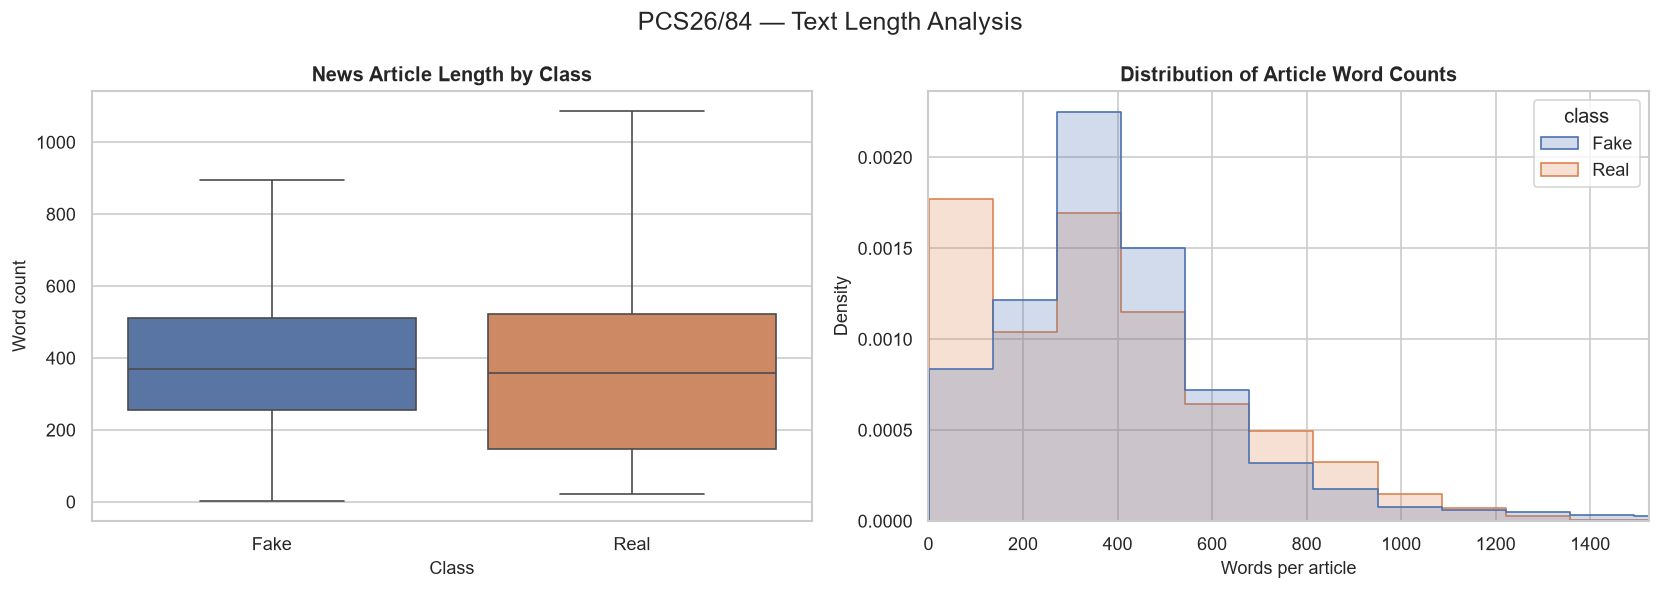

In [12]:

text_stats = df_clean[["title", "text", "label"]].copy()

text_stats["class"] = text_stats["label"].map(LABEL_MAP)
text_stats["text_characters"] = text_stats["text"].str.len()
text_stats["text_words"] = (
    text_stats["text"].astype(str).str.split().str.len()
)
text_stats["title_words"] = (
    text_stats["title"].astype(str).str.split().str.len()
)

length_summary = (
    text_stats.groupby("class")[
        ["text_characters", "text_words", "title_words"]
    ]
    .agg(["count", "mean", "median", "std", "min", "max"])
    .round(2)
)

display(length_summary)

length_summary.to_csv(
    TABLES_DIR / "text_length_summary.csv"
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(
    data=text_stats,
    x="class",
    y="text_words",
    hue="class",
    legend=False,
    showfliers=False,
    ax=axes[0]
)
axes[0].set_title("News Article Length by Class")
axes[0].set_xlabel("Class")
axes[0].set_ylabel("Word count")

sns.histplot(
    data=text_stats,
    x="text_words",
    hue="class",
    bins=60,
    element="step",
    stat="density",
    common_norm=False,
    ax=axes[1]
)
axes[1].set_xlim(0, text_stats["text_words"].quantile(0.99))
axes[1].set_title("Distribution of Article Word Counts")
axes[1].set_xlabel("Words per article")
axes[1].set_ylabel("Density")

fig.suptitle("PCS26/84 — Text Length Analysis", fontsize=15)
fig.savefig(FIGURES_DIR / "02_text_length_analysis.png", bbox_inches="tight")
plt.show()

**Interpretation (length statistics and plots).** Body length differs only modestly between classes (mean 434.9 words Fake vs 384.8 Real; medians 369 vs 359), although Real has a concentration of short articles and Fake a long right tail. **Headline length differs strongly**: Fake headlines average 14.7 words (SD 4.3) and Real 9.95 (SD 1.7), with Real headlines never above 20 words. In the training partition the headline-length ROC-AUC is 0.126 (separation 0.75) whereas body-length AUC is close to chance (0.467). *Caution:* a distributional difference describes the dataset; it does not show that length *causes* a text to be fake.

label,Fake,Real,Total
subject_clean,,,
politicsNews,0,11219,11219
worldnews,0,9991,9991
News,9050,0,9050
politics,6430,0,6430
left-news,4309,0,4309
Government News,1498,0,1498
US_News,783,0,783
Middle-east,778,0,778


,Metric,Value
0,Total cleaned records,44058
1,Successfully parsed dates,44048
2,Unparseable dates,10
3,Unique publication dates,1010


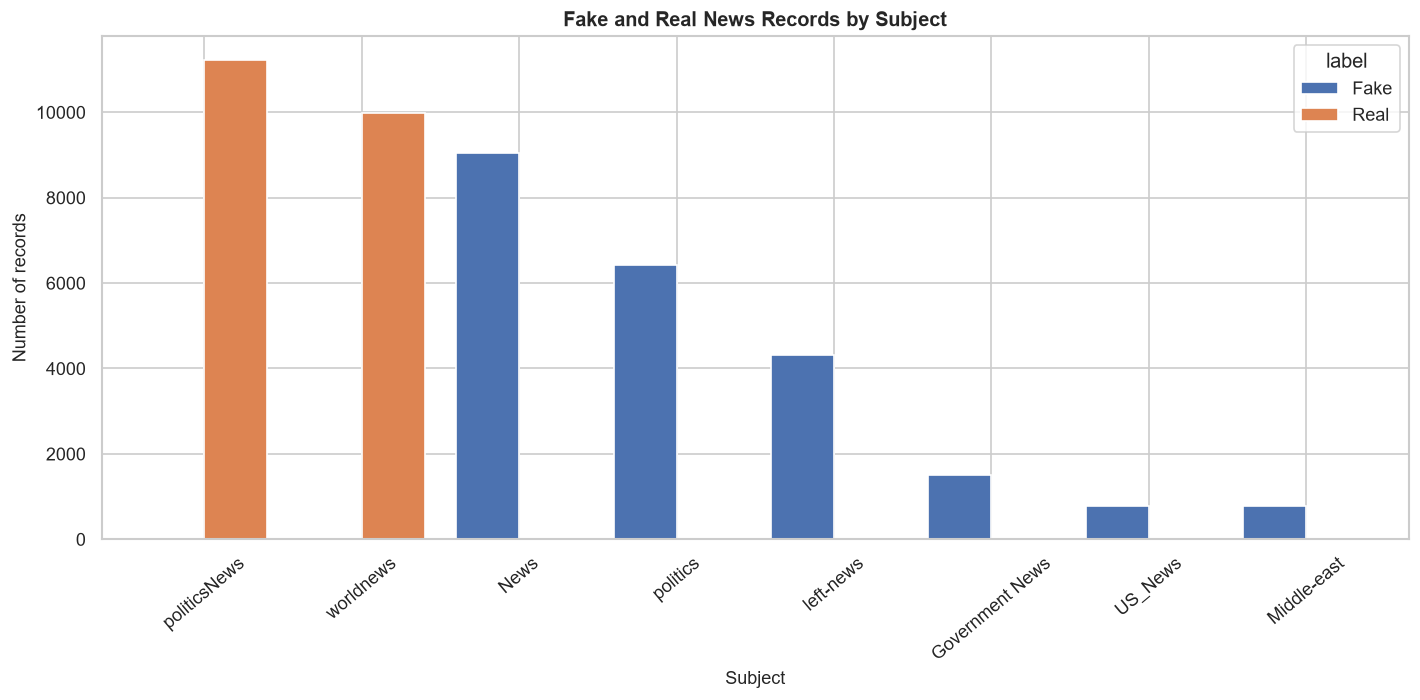

C:\Users\mi\AppData\Local\Temp\ipykernel_26556\1428893972.py:84: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  valid_dates["date_parsed"].dt.to_period("M").astype(str)


label,Fake,Real
publication_month,,
2015-03,8,0
2015-04,309,0
2015-05,302,0
2015-06,232,0
2015-07,290,0


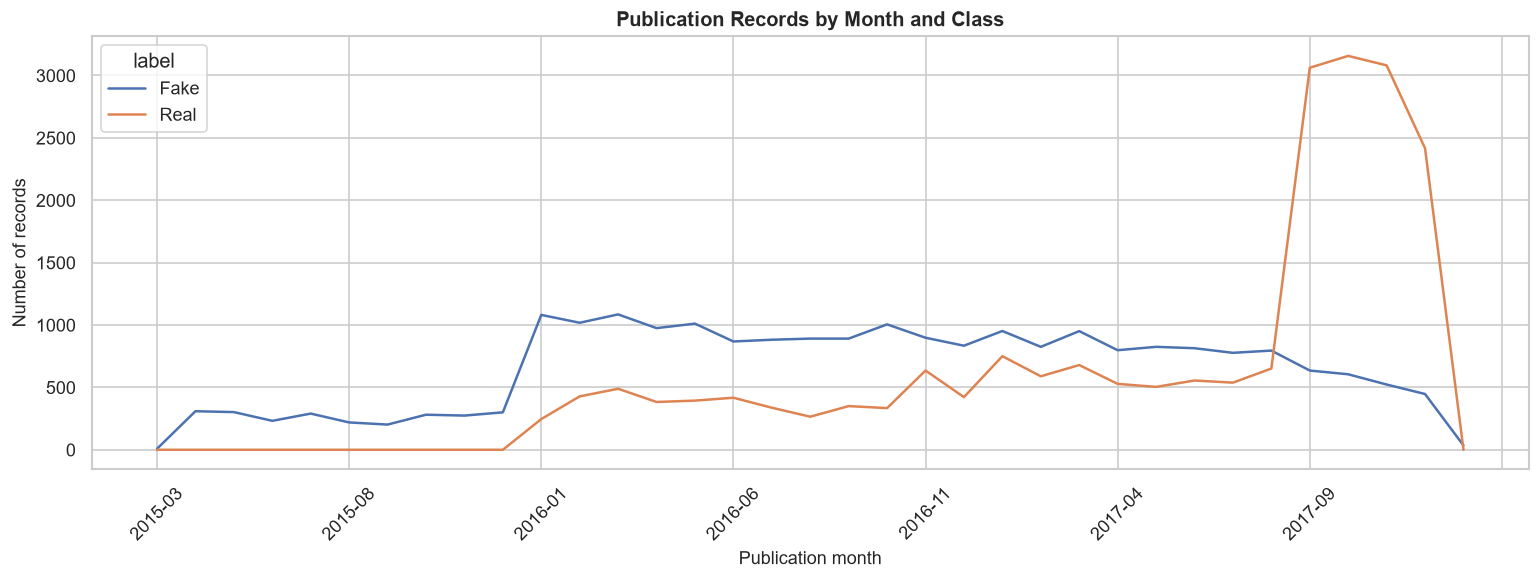

In [13]:

# Subject and publication-date analysis
metadata_df = df_clean.copy()

metadata_df["subject_clean"] = (
    metadata_df["subject"]
    .fillna("Unknown")
    .astype(str)
    .str.strip()
    .replace("", "Unknown")
)

metadata_df["date_parsed"] = pd.to_datetime(
    metadata_df["date"].astype(str).str.strip(),
    errors="coerce",
    format="mixed",
    utc=True
)

# 1. Subject distribution by class
subject_summary = (
    metadata_df.groupby(["subject_clean", "label"])
    .size()
    .unstack(fill_value=0)
    .rename(columns={0: "Fake", 1: "Real"})
)

subject_summary["Total"] = subject_summary.sum(axis=1)
subject_summary = subject_summary.sort_values("Total", ascending=False)

display(subject_summary)

subject_summary.to_csv(
    TABLES_DIR / "subject_distribution_by_class.csv"
)

# 2. Date parsing quality
date_quality = pd.DataFrame({
    "Metric": [
        "Total cleaned records",
        "Successfully parsed dates",
        "Unparseable dates",
        "Unique publication dates"
    ],
    "Value": [
        len(metadata_df),
        int(metadata_df["date_parsed"].notna().sum()),
        int(metadata_df["date_parsed"].isna().sum()),
        int(metadata_df["date_parsed"].nunique())
    ]
})

display(date_quality)

date_quality.to_csv(
    TABLES_DIR / "date_quality_audit.csv", index=False
)

# 3. Subject chart
subject_plot = subject_summary[["Fake", "Real"]]

ax = subject_plot.plot(
    kind="bar",
    figsize=(12, 6),
    width=0.8
)
ax.set_title("Fake and Real News Records by Subject")
ax.set_xlabel("Subject")
ax.set_ylabel("Number of records")
ax.tick_params(axis="x", rotation=40)
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "03_subject_distribution.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# 4. Monthly publication trend, if enough dates are valid
valid_dates = metadata_df.dropna(subset=["date_parsed"]).copy()

if not valid_dates.empty:
    valid_dates["publication_month"] = (
        valid_dates["date_parsed"].dt.to_period("M").astype(str)
    )

    monthly_counts = (
        valid_dates.groupby(["publication_month", "label"])
        .size()
        .unstack(fill_value=0)
        .rename(columns={0: "Fake", 1: "Real"})
        .sort_index()
    )

    display(monthly_counts.head())
    monthly_counts.to_csv(
        TABLES_DIR / "monthly_publication_counts.csv"
    )

    ax = monthly_counts.plot(figsize=(13, 5))
    ax.set_title("Publication Records by Month and Class")
    ax.set_xlabel("Publication month")
    ax.set_ylabel("Number of records")
    plt.xticks(rotation=45)
    plt.tight_layout()

    plt.savefig(
        FIGURES_DIR / "04_monthly_publication_trend.png",
        dpi=300,
        bbox_inches="tight"
    )
    plt.show()
else:
    print("No valid publication dates were available for trend analysis.")

**Interpretation (subject and date).** Every subject is 100 % one class (six Fake-only subjects; two Real-only subjects, `politicsNews` and `worldnews`), so `subject` is a perfect label proxy and is excluded from all models. Dates span 2015-03 to 2018-02 for Fake but only 2016-01 to 2017-12 for Real, so any date before 2016 is automatically Fake; `date` is therefore also excluded. Ten dates could not be parsed and were left out of the monthly trend only.

In [14]:
# Round-trip check: the saved clean CSV (used by Notebooks 02 and 03 and by the
# split manifest) must equal the in-memory cleaned data used for the EDA below.
DATASET_PATH = DATA_DIR / "combined_fake_news_clean.csv"
assert DATASET_PATH.exists(), f"Cleaned dataset not found at: {DATASET_PATH}"

df_disk = pd.read_csv(DATASET_PATH)
assert df_disk.shape == df_clean.shape, (df_disk.shape, df_clean.shape)
for col in ["title", "text", "subject", "date", "label"]:
    assert df_disk[col].fillna("").astype(str).equals(
        df_clean[col].fillna("").astype(str)), f"Column {col} differs from the saved CSV"

print("Saved clean CSV matches the in-memory cleaned data.")
print("Shape:", df_disk.shape)
print(df_clean["label"].value_counts())

Saved clean CSV matches the in-memory cleaned data.
Shape: (44058, 5)
label
0    22848
1    21210
Name: count, dtype: int64


##  Subject–Label Relationship Analysis

This analysis examines the distribution of fake and real news across different subject categories. It also helps identify potential dataset bias and features that should not be used directly for classification.


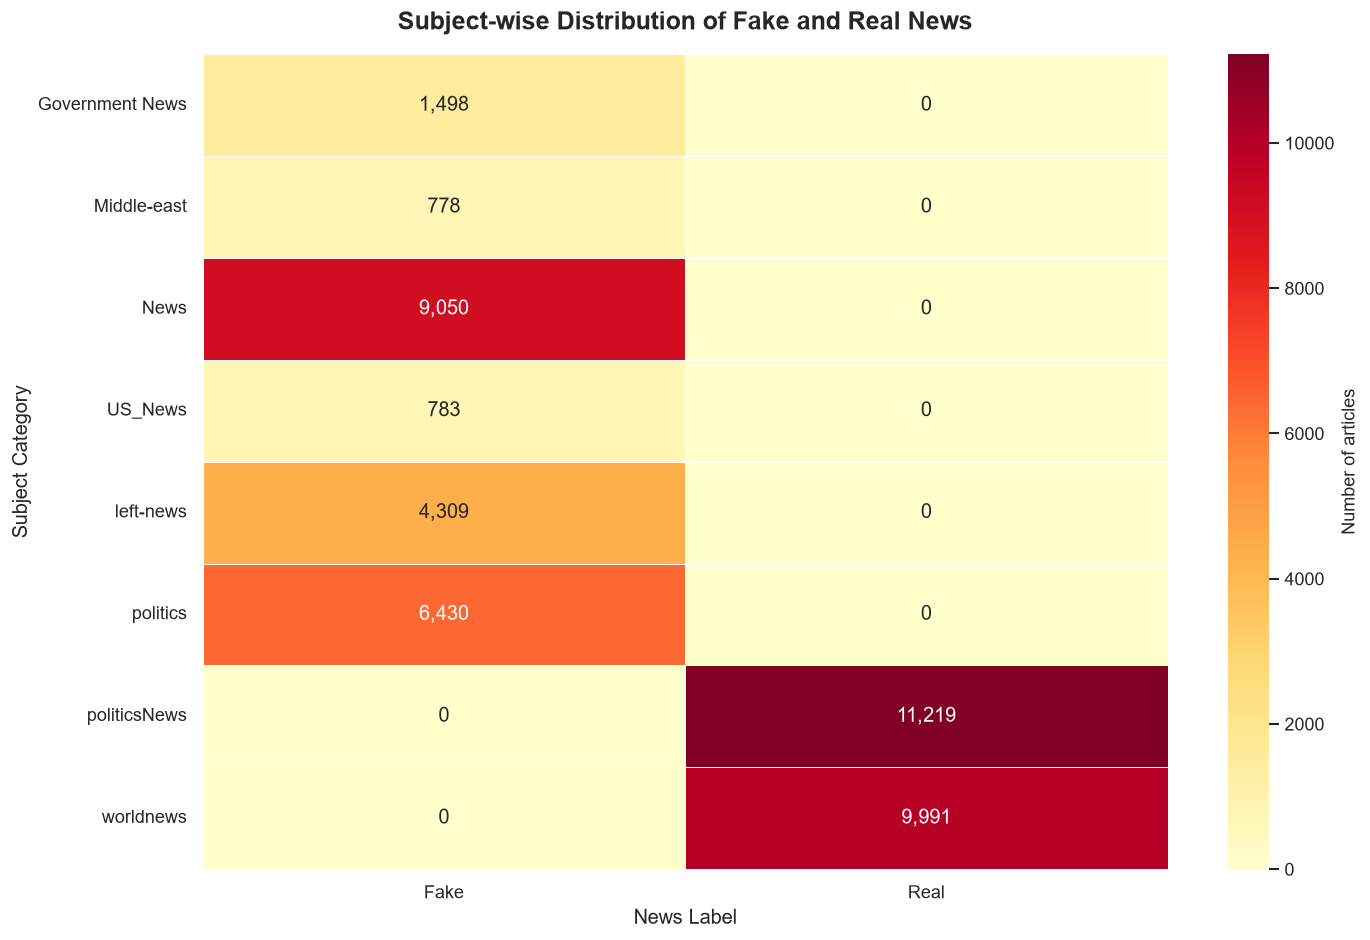

Subject-label heatmap generated successfully.
Saved: results/figures/05_subject_label_heatmap.png
Saved: results/tables/subject_label_distribution.csv


In [15]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Use the cleaned dataset
eda_df = df_clean.copy()

# Count Fake and Real articles by subject
subject_label_counts = pd.crosstab(
    eda_df["subject"],
    eda_df["label"].map({0: "Fake", 1: "Real"})
)

# Save the frequency table
subject_label_counts.to_csv(
    RESULTS_TABLES / "subject_label_distribution.csv"
)

# Plot the heatmap
plt.figure(figsize=(12, 8))

sns.heatmap(
    subject_label_counts,
    annot=True,
    fmt=",",
    cmap="YlOrRd",
    linewidths=0.5,
    cbar_kws={"label": "Number of articles"}
)

plt.title(
    "Subject-wise Distribution of Fake and Real News",
    fontsize=15,
    fontweight="bold",
    pad=15
)
plt.xlabel("News Label", fontsize=12)
plt.ylabel("Subject Category", fontsize=12)
plt.xticks(rotation=0)
plt.yticks(rotation=0)
plt.tight_layout()

# Save figure
plt.savefig(
    RESULTS_FIGURES / "05_subject_label_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Subject-label heatmap generated successfully.")
print("Saved: results/figures/05_subject_label_heatmap.png")
print("Saved: results/tables/subject_label_distribution.csv")

**Interpretation (subject–label heatmap).** The heatmap is block-diagonal: no subject mixes classes. This is not evidence that politics-style subjects *cause* fake news; it reflects how the corpus was assembled (Real from one agency's feed, Fake from several sites).

##  Word Cloud Analysis

Word clouds visualize frequently occurring words in fake and real news articles. This analysis helps explore differences in vocabulary between the two classes. Word frequency alone does not establish whether a news article is true or false.


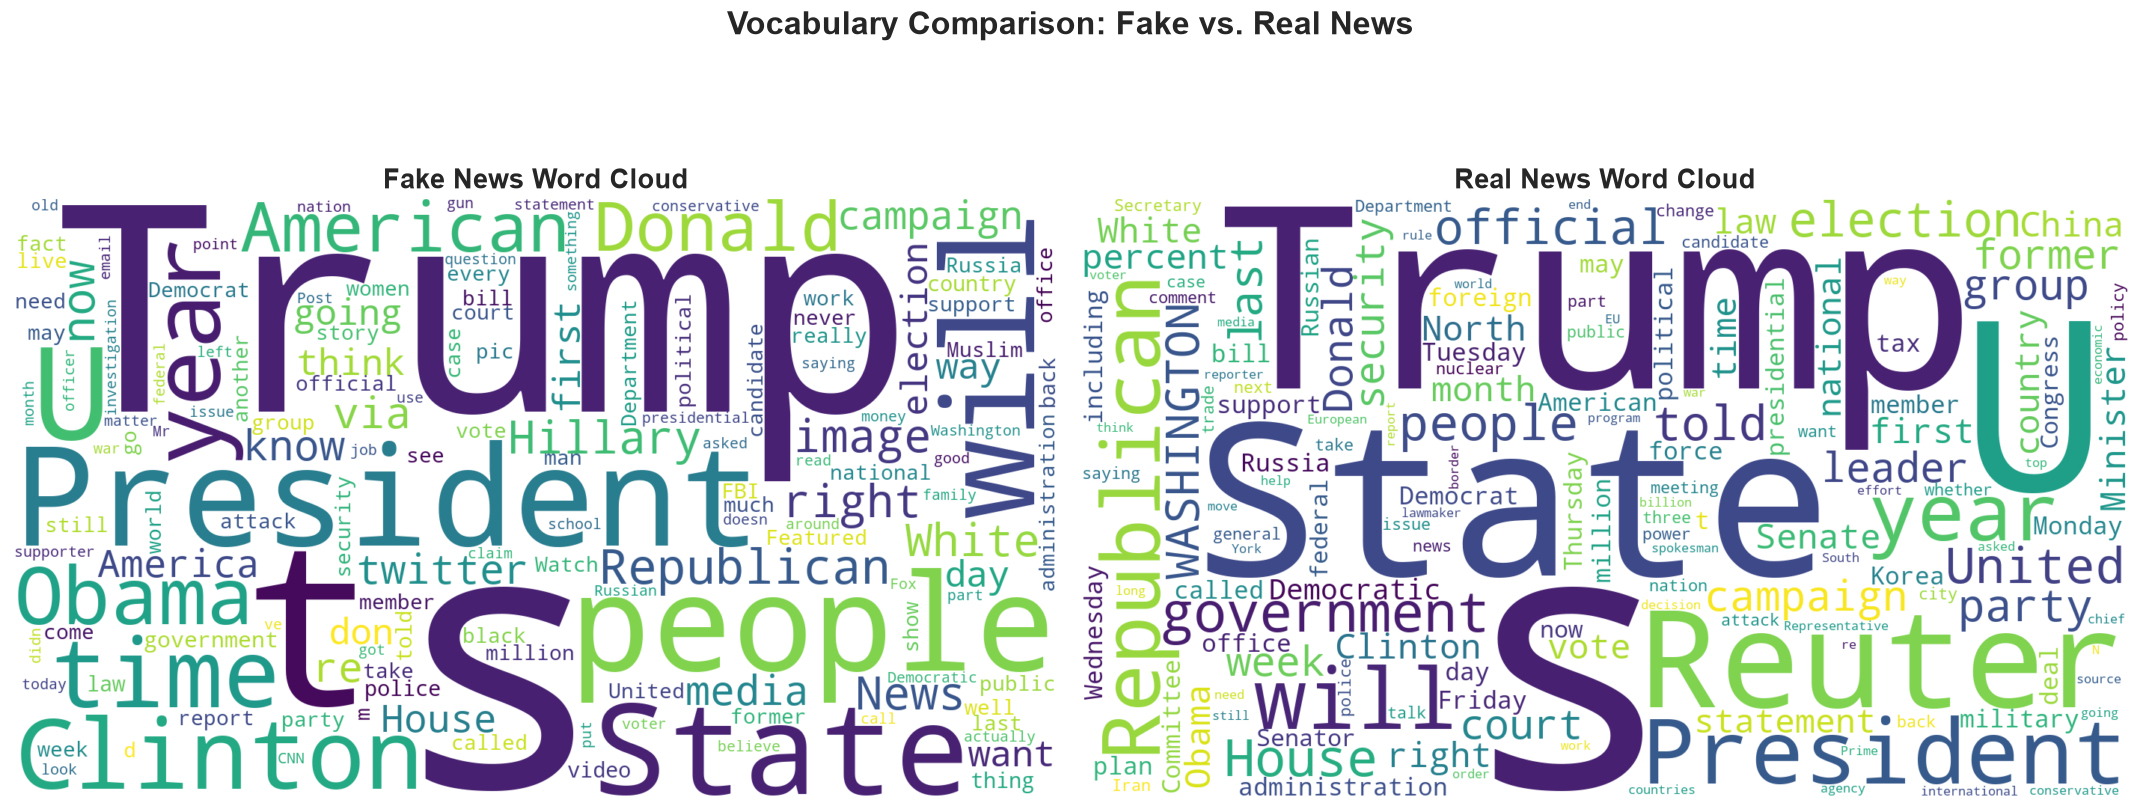

Word clouds generated successfully.
Saved to: C:\Users\mi\Desktop\Fake-news detection\results\figures\06_fake_vs_real_wordclouds.png


In [16]:
from wordcloud import WordCloud
import matplotlib.pyplot as plt

# Confirm the required columns exist
required_columns = {"text", "label"}
missing_columns = required_columns - set(df_clean.columns)

if missing_columns:
    raise ValueError(f"Missing required columns: {missing_columns}")

# Labels: 0 = Fake, 1 = Real
fake_text = " ".join(
    df_clean.loc[df_clean["label"] == 0, "text"]
    .dropna()
    .astype(str)
)

real_text = " ".join(
    df_clean.loc[df_clean["label"] == 1, "text"]
    .dropna()
    .astype(str)
)

# Common words that add little analytical value
stop_words = set(WordCloud().stopwords)
stop_words.update({
    "said", "would", "could", "also", "one",
    "two", "new", "say", "says", "get",
    "like", "even", "make", "made", "many",
    "according", "reported"
    # NOTE: "reuters" is deliberately NOT removed. Hiding it would conceal the
    # most obvious publisher marker in the dataset (see the marker analysis).
})

# Generate word clouds
fake_cloud = WordCloud(
    width=1400,
    height=800,
    background_color="white",
    stopwords=stop_words,
    max_words=150,
    collocations=False,
    random_state=42
).generate(fake_text)

real_cloud = WordCloud(
    width=1400,
    height=800,
    background_color="white",
    stopwords=stop_words,
    max_words=150,
    collocations=False,
    random_state=42
).generate(real_text)

# Display side-by-side comparison
fig, axes = plt.subplots(1, 2, figsize=(18, 8))

axes[0].imshow(fake_cloud, interpolation="bilinear")
axes[0].set_title("Fake News Word Cloud", fontsize=16, fontweight="bold")
axes[0].axis("off")

axes[1].imshow(real_cloud, interpolation="bilinear")
axes[1].set_title("Real News Word Cloud", fontsize=16, fontweight="bold")
axes[1].axis("off")

fig.suptitle(
    "Vocabulary Comparison: Fake vs. Real News",
    fontsize=19,
    fontweight="bold"
)
plt.tight_layout()

# Save high-resolution figure
output_path = RESULTS_FIGURES / "06_fake_vs_real_wordclouds.png"
plt.savefig(output_path, dpi=300, bbox_inches="tight")
plt.show()

print("Word clouds generated successfully.")
print("Saved to:", output_path)

**Interpretation (word clouds).** Word clouds show frequency, not importance, and common words (*said, trump, president*) appear in both classes. The token `reuters` is deliberately **not** hidden here, because hiding it would conceal the most obvious publisher marker in the data.

##  Most Frequent Words Analysis

This analysis identifies the most frequent words in fake and real news articles after removing common English stop words. Comparing word frequencies helps reveal vocabulary patterns in the selected dataset.


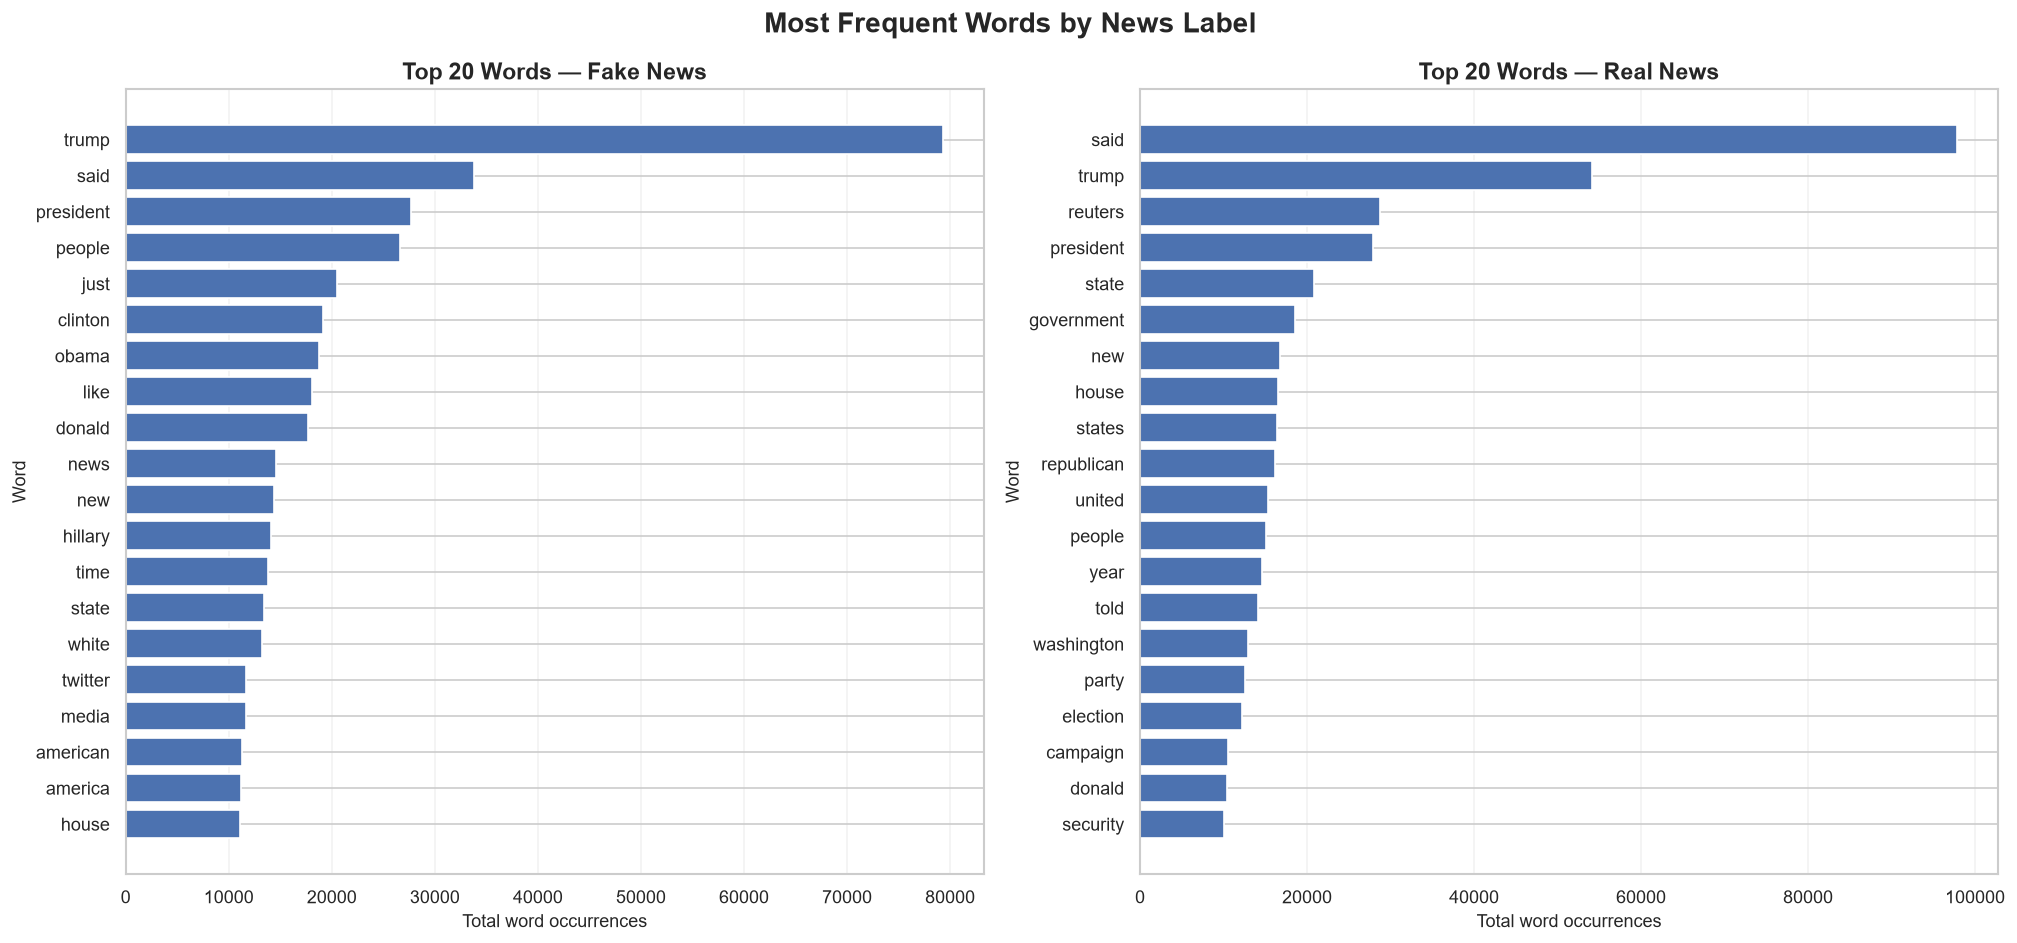

Top-word analysis completed.
Saved figure: C:\Users\mi\Desktop\Fake-news detection\results\figures\07_top_frequent_words.png
Saved table: C:\Users\mi\Desktop\Fake-news detection\results\tables\top_20_words_by_label.csv


In [17]:

from sklearn.feature_extraction.text import CountVectorizer
import pandas as pd
import matplotlib.pyplot as plt

# Separate article text by label
fake_articles = (
    df_clean.loc[df_clean["label"] == 0, "text"]
    .dropna()
    .astype(str)
)

real_articles = (
    df_clean.loc[df_clean["label"] == 1, "text"]
    .dropna()
    .astype(str)
)

# Limit vocabulary size to keep memory use reasonable
vectorizer = CountVectorizer(
    stop_words="english",
    max_features=10000,
    min_df=5,
    max_df=0.90,
    lowercase=True,
    token_pattern=r"(?u)\b[a-zA-Z]{2,}\b"
)

# Fit on the combined training-independent EDA corpus
# This is descriptive analysis, not model training.
all_articles = pd.concat([fake_articles, real_articles])
vectorizer.fit(all_articles)

vocabulary = vectorizer.get_feature_names_out()

def get_top_words(articles, label, top_n=20):
    counts = vectorizer.transform(articles).sum(axis=0).A1

    word_counts = pd.DataFrame({
        "word": vocabulary,
        "frequency": counts
    })

    word_counts = (
        word_counts.sort_values("frequency", ascending=False)
        .head(top_n)
        .copy()
    )
    word_counts["label"] = label
    return word_counts

fake_top_words = get_top_words(fake_articles, "Fake")
real_top_words = get_top_words(real_articles, "Real")

# Save results
top_words = pd.concat(
    [fake_top_words, real_top_words],
    ignore_index=True
)

top_words.to_csv(
    RESULTS_TABLES / "top_20_words_by_label.csv",
    index=False
)

# Plot separate panels for clarity
fig, axes = plt.subplots(1, 2, figsize=(17, 8))

for ax, data, title in [
    (axes[0], fake_top_words, "Top 20 Words — Fake News"),
    (axes[1], real_top_words, "Top 20 Words — Real News")
]:
    data = data.sort_values("frequency", ascending=True)
    ax.barh(data["word"], data["frequency"])
    ax.set_title(title, fontsize=14, fontweight="bold")
    ax.set_xlabel("Total word occurrences")
    ax.set_ylabel("Word")
    ax.grid(axis="x", alpha=0.25)

fig.suptitle(
    "Most Frequent Words by News Label",
    fontsize=17,
    fontweight="bold"
)
plt.tight_layout()

output_path = RESULTS_FIGURES / "07_top_frequent_words.png"
plt.savefig(output_path, dpi=300, bbox_inches="tight")
plt.show()

print("Top-word analysis completed.")
print("Saved figure:", output_path)
print("Saved table:", RESULTS_TABLES / "top_20_words_by_label.csv")

**Interpretation (most frequent words).** Both classes are dominated by US-politics vocabulary (*trump, president, state*). `reuters` is the third most frequent word in Real articles and is absent from the Fake top 20. Fake's top words include informal, opinion-style tokens (*just, like, people, news*), whereas Real's include wire-reporting vocabulary (*said, told, government*). These are *associations in this corpus*, not definitions of fake news.

##  Bigram Frequency Analysis

Bigram analysis identifies frequently occurring two-word phrases in fake and real news articles. It provides additional insight into language patterns beyond individual word frequencies.


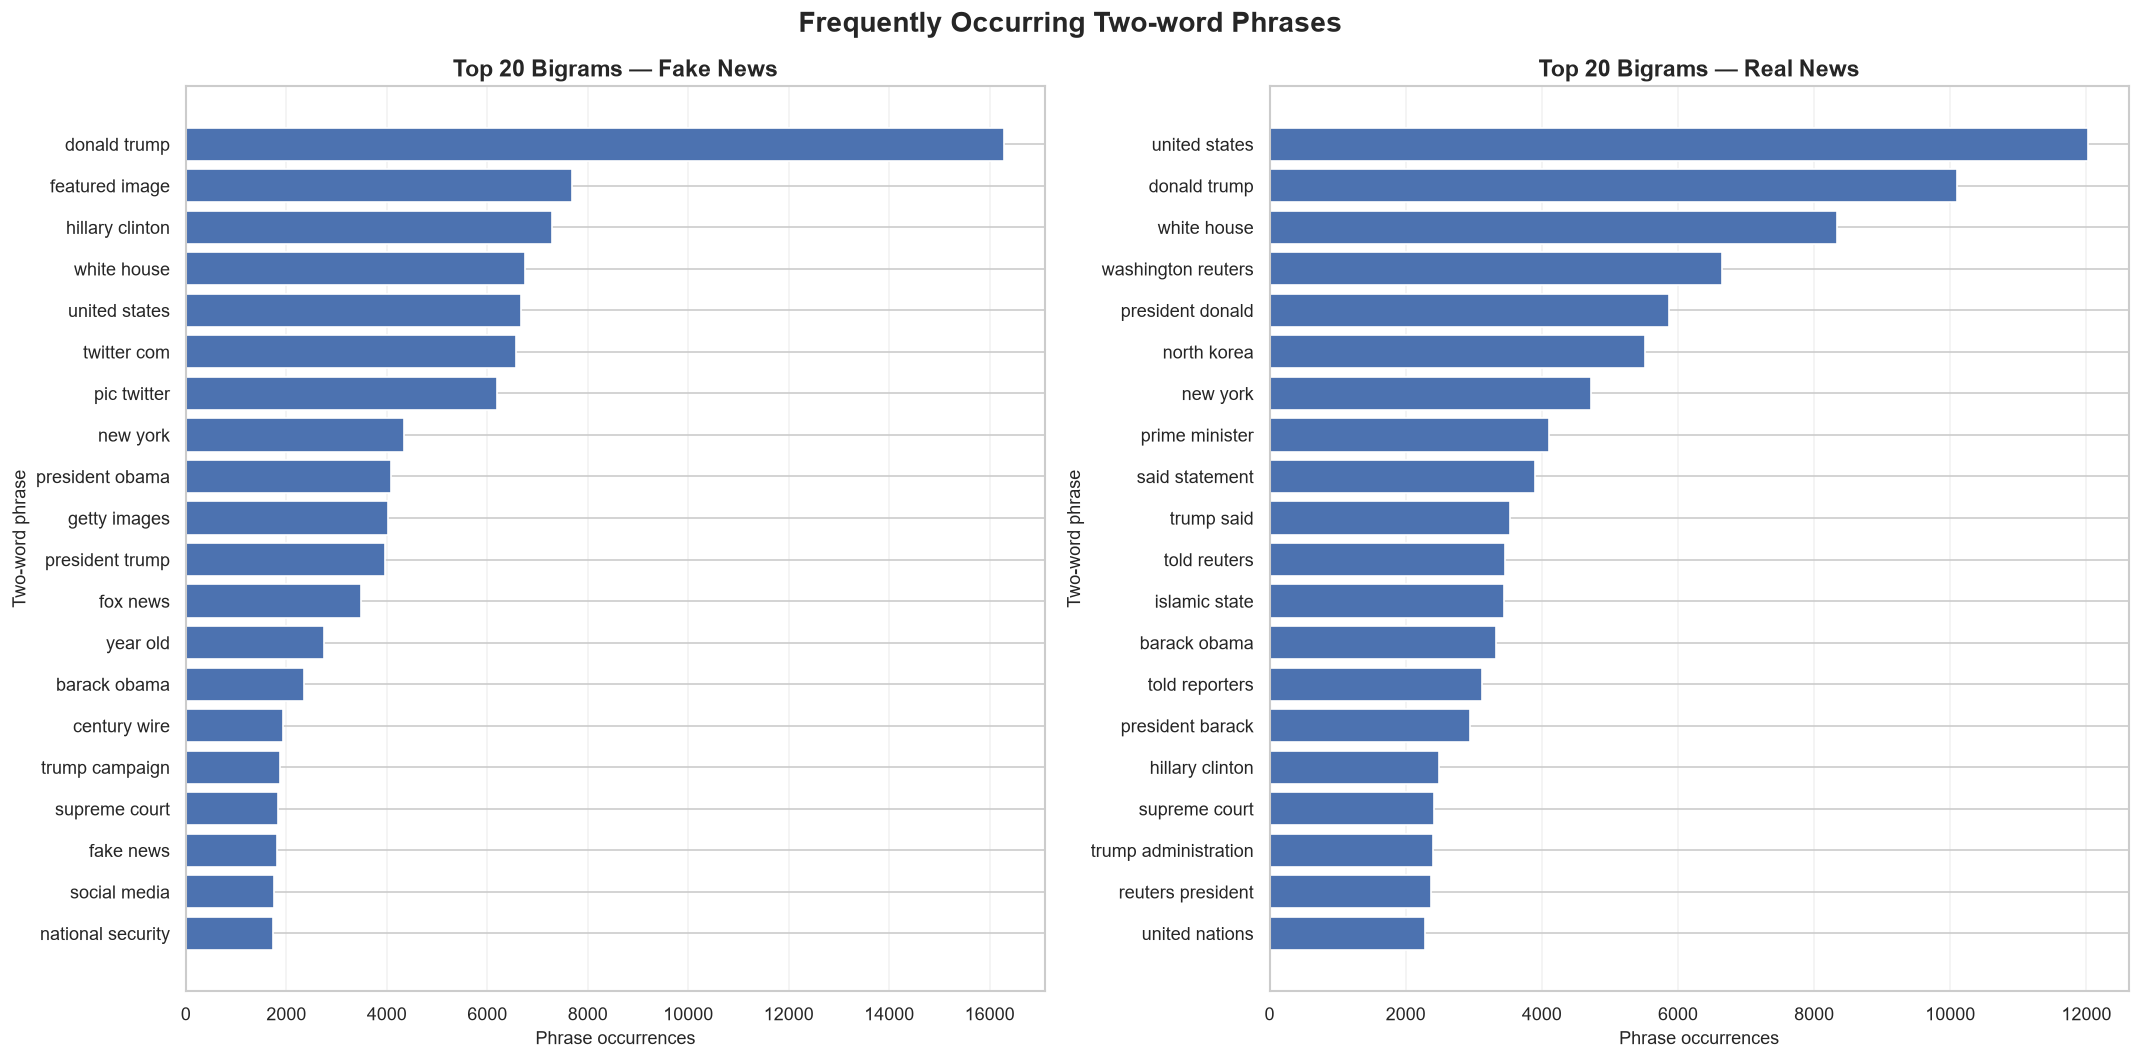

Bigram analysis completed.
Saved figure: C:\Users\mi\Desktop\Fake-news detection\results\figures\08_top_bigrams.png
Saved table: C:\Users\mi\Desktop\Fake-news detection\results\tables\top_20_bigrams_by_label.csv


In [18]:

from sklearn.feature_extraction.text import CountVectorizer
import pandas as pd
import matplotlib.pyplot as plt

# Use article text separately for each class
fake_articles = (
    df_clean.loc[df_clean["label"] == 0, "text"]
    .dropna()
    .astype(str)
)

real_articles = (
    df_clean.loc[df_clean["label"] == 1, "text"]
    .dropna()
    .astype(str)
)

bigram_vectorizer = CountVectorizer(
    stop_words="english",
    ngram_range=(2, 2),
    max_features=5000,
    min_df=5,
    max_df=0.90,
    lowercase=True,
    token_pattern=r"(?u)\b[a-zA-Z]{2,}\b"
)

def get_top_bigrams(articles, label, top_n=20):
    matrix = bigram_vectorizer.fit_transform(articles)
    frequencies = matrix.sum(axis=0).A1
    phrases = bigram_vectorizer.get_feature_names_out()

    result = pd.DataFrame({
        "bigram": phrases,
        "frequency": frequencies,
        "label": label
    })

    return result.sort_values(
        "frequency", ascending=False
    ).head(top_n)

fake_bigrams = get_top_bigrams(fake_articles, "Fake")
real_bigrams = get_top_bigrams(real_articles, "Real")

# Save frequency tables
all_bigrams = pd.concat(
    [fake_bigrams, real_bigrams],
    ignore_index=True
)

all_bigrams.to_csv(
    RESULTS_TABLES / "top_20_bigrams_by_label.csv",
    index=False
)

# Plot two side-by-side charts
fig, axes = plt.subplots(1, 2, figsize=(18, 9))

for ax, data, title in [
    (axes[0], fake_bigrams, "Top 20 Bigrams — Fake News"),
    (axes[1], real_bigrams, "Top 20 Bigrams — Real News")
]:
    data = data.sort_values("frequency", ascending=True)
    ax.barh(data["bigram"], data["frequency"])
    ax.set_title(title, fontsize=14, fontweight="bold")
    ax.set_xlabel("Phrase occurrences")
    ax.set_ylabel("Two-word phrase")
    ax.grid(axis="x", alpha=0.25)

fig.suptitle(
    "Frequently Occurring Two-word Phrases",
    fontsize=17,
    fontweight="bold"
)

plt.tight_layout()

output_path = RESULTS_FIGURES / "08_top_bigrams.png"
plt.savefig(output_path, dpi=300, bbox_inches="tight")
plt.show()

print("Bigram analysis completed.")
print("Saved figure:", output_path)
print(
    "Saved table:",
    RESULTS_TABLES / "top_20_bigrams_by_label.csv"
)

**Interpretation (bigrams).** The most frequent Fake bigrams include web and social-media artefacts — *featured image* (7,692 occurrences), *twitter com* (6,567) and *pic twitter* (6,195) — next to political names. Such bigrams describe page furniture rather than reporting content and foreshadow the marker analysis below.

##  Article Length Comparison by News Label

This analysis compares the distribution of article word counts for fake and real news. Boxplots and histograms help identify differences in article length, variability, and unusually short or long articles.


,count,mean,std,min,25%,50%,75%,max
label_name,,,,,,,,
Fake,22848.0,434.89,407.82,1.0,254.0,369.0,511.0,8135.0
Real,21210.0,384.78,273.90,22.0,147.0,359.0,523.0,5172.0


c:\Users\mi\Desktop\Fake-news detection\.venv\Lib\site-packages\seaborn\categorical.py:700: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)


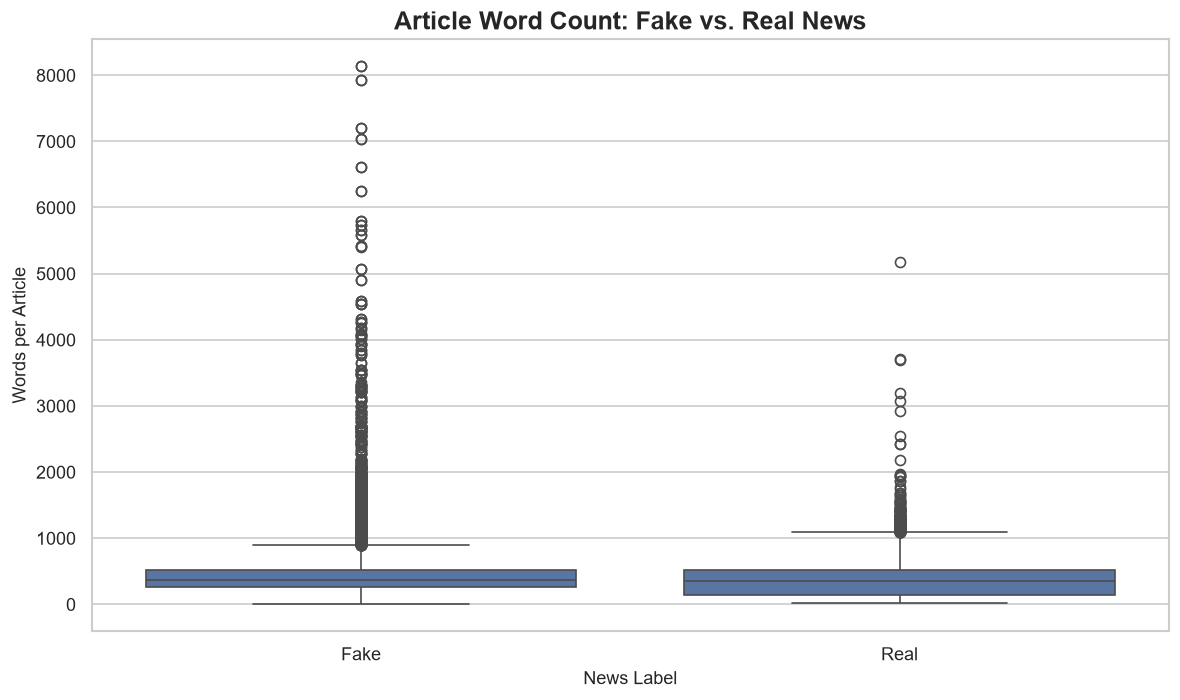

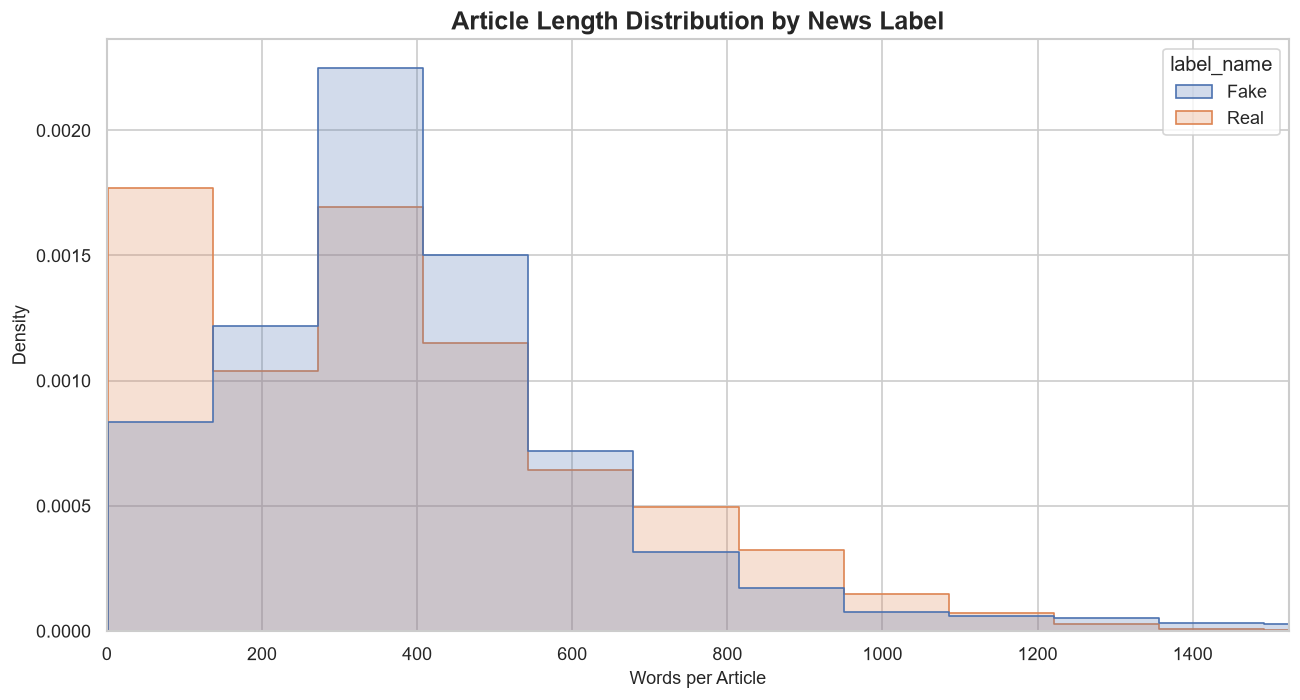

Article length analysis completed.
Saved: C:\Users\mi\Desktop\Fake-news detection\results\figures\09_article_length_boxplot.png
Saved: C:\Users\mi\Desktop\Fake-news detection\results\figures\10_article_length_distribution.png
Saved: C:\Users\mi\Desktop\Fake-news detection\results\tables\article_length_summary.csv


In [19]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Work on a copy; preserve the cleaned dataset
length_df = df_clean[["text", "label"]].copy()

length_df["label_name"] = length_df["label"].map({
    0: "Fake",
    1: "Real"
})

# Count words in each article
length_df["word_count"] = (
    length_df["text"]
    .fillna("")
    .astype(str)
    .str.split()
    .str.len()
)

# Save summary statistics
length_summary = (
    length_df.groupby("label_name")["word_count"]
    .describe()
    .round(2)
)

length_summary.to_csv(
    RESULTS_TABLES / "article_length_summary.csv"
)

display(length_summary)

# Boxplot comparison
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=length_df,
    x="label_name",
    y="word_count"
)

plt.title(
    "Article Word Count: Fake vs. Real News",
    fontsize=15,
    fontweight="bold"
)
plt.xlabel("News Label")
plt.ylabel("Words per Article")
plt.tight_layout()

boxplot_path = RESULTS_FIGURES / "09_article_length_boxplot.png"
plt.savefig(boxplot_path, dpi=300, bbox_inches="tight")
plt.show()

# Histogram comparison; limit x-axis to improve readability
plt.figure(figsize=(11, 6))

sns.histplot(
    data=length_df,
    x="word_count",
    hue="label_name",
    bins=60,
    element="step",
    stat="density",
    common_norm=False
)

plt.xlim(0, length_df["word_count"].quantile(0.99))
plt.title(
    "Article Length Distribution by News Label",
    fontsize=15,
    fontweight="bold"
)
plt.xlabel("Words per Article")
plt.ylabel("Density")
plt.tight_layout()

hist_path = RESULTS_FIGURES / "10_article_length_distribution.png"
plt.savefig(hist_path, dpi=300, bbox_inches="tight")
plt.show()

print("Article length analysis completed.")
print("Saved:", boxplot_path)
print("Saved:", hist_path)
print(
    "Saved:",
    RESULTS_TABLES / "article_length_summary.csv"
)

**Interpretation (article length plots).** The box-plot and histogram show heavily right-skewed lengths in both classes with substantial overlap in the middle of the distribution (Fake max 8,135 words, Real max 5,172). Length alone therefore cannot classify an article, but the tail and the very-short-body behaviour noted above leave small class-specific regions.

##  News Title Length Analysis

This analysis compares headline length across fake and real news articles. It explores whether title length varies between the two classes, without assuming that headline length alone can determine news authenticity.


title_word_count                                            \
                      count   mean   std  min   25%   50%   75%   max   
label_name                                                              
Fake                22848.0  14.73  4.33  1.0  12.0  14.0  17.0  42.0   
Real                21210.0   9.95  1.70  4.0   9.0  10.0  11.0  20.0   

           title_char_count                                                
                      count   mean    std   min   25%   50%    75%    max  
label_name                                                                 
Fake                22848.0  94.22  27.24   8.0  77.0  90.0  105.0  286.0  
Real                21210.0  64.66   9.16  26.0  59.0  64.0   70.0  133.0

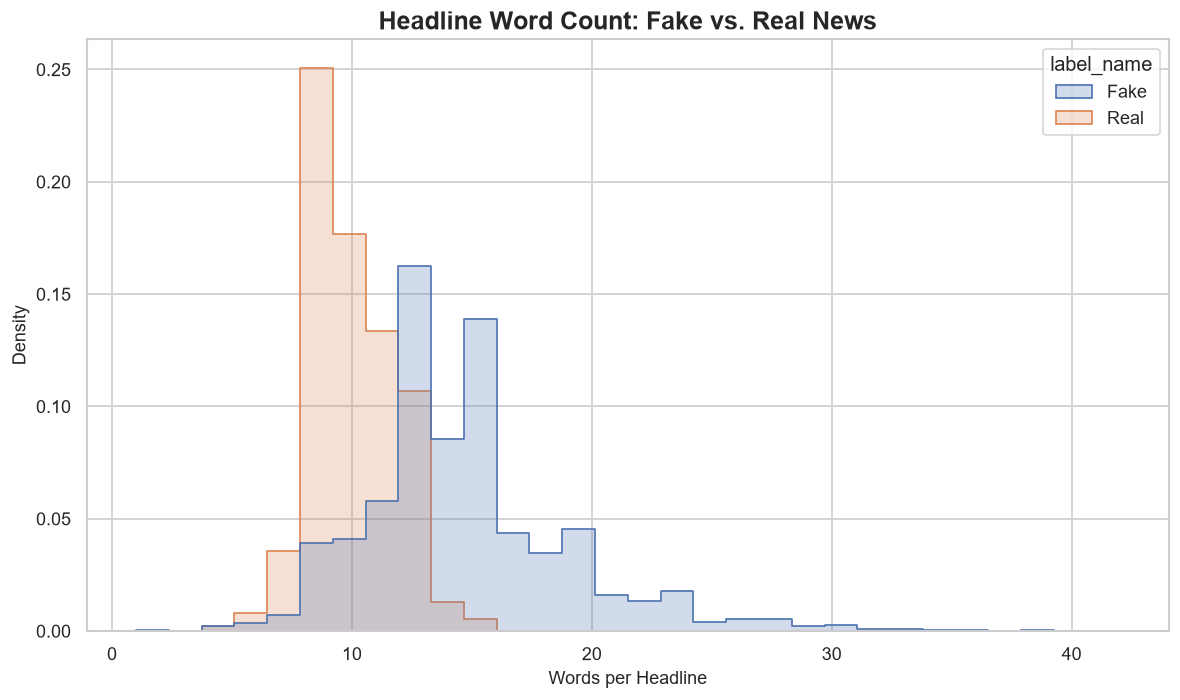

c:\Users\mi\Desktop\Fake-news detection\.venv\Lib\site-packages\seaborn\categorical.py:700: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)


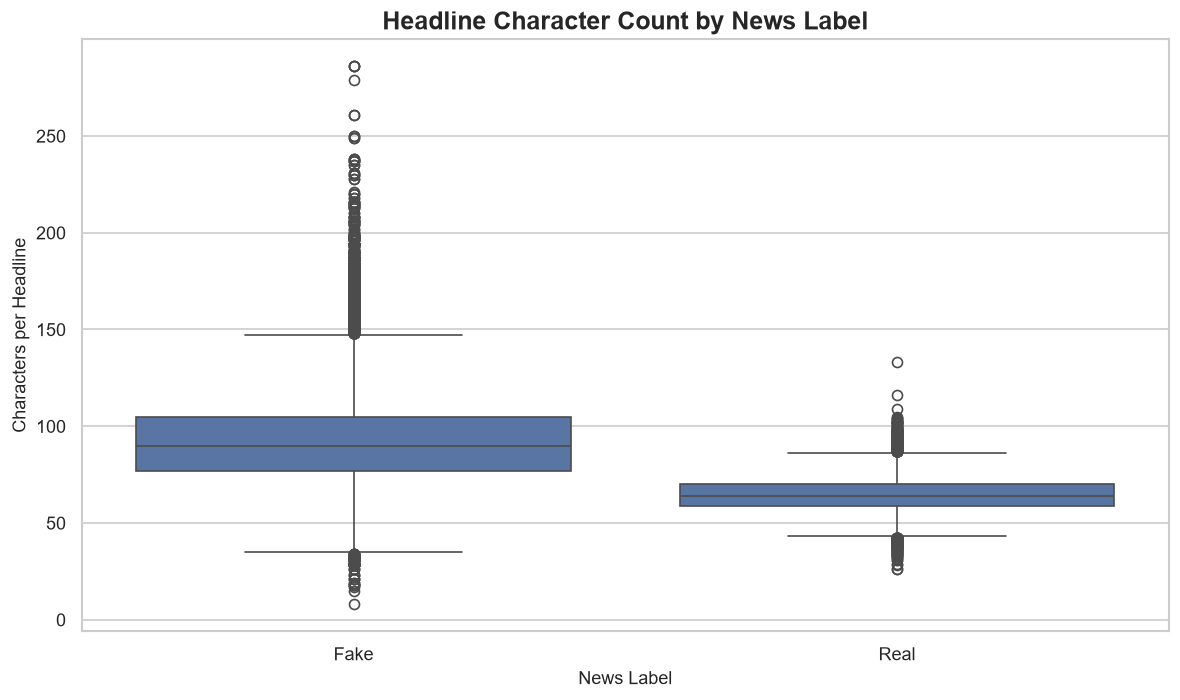

Title length analysis completed.
Saved: C:\Users\mi\Desktop\Fake-news detection\results\figures\11_title_word_count.png
Saved: C:\Users\mi\Desktop\Fake-news detection\results\figures\12_title_character_count.png
Saved: C:\Users\mi\Desktop\Fake-news detection\results\tables\title_length_summary.csv


In [20]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Use title and label only
title_df = df_clean[["title", "label"]].copy()

title_df["label_name"] = title_df["label"].map({
    0: "Fake",
    1: "Real"
})

title_df["title_word_count"] = (
    title_df["title"]
    .fillna("")
    .astype(str)
    .str.split()
    .str.len()
)

title_df["title_char_count"] = (
    title_df["title"]
    .fillna("")
    .astype(str)
    .str.len()
)

# Save summary statistics
title_summary = (
    title_df.groupby("label_name")[
        ["title_word_count", "title_char_count"]
    ]
    .describe()
    .round(2)
)

title_summary.to_csv(
    RESULTS_TABLES / "title_length_summary.csv"
)

display(title_summary)

# Plot 1: Title word-count distribution
plt.figure(figsize=(10, 6))

sns.histplot(
    data=title_df,
    x="title_word_count",
    hue="label_name",
    bins=30,
    element="step",
    stat="density",
    common_norm=False
)

plt.title(
    "Headline Word Count: Fake vs. Real News",
    fontsize=15,
    fontweight="bold"
)
plt.xlabel("Words per Headline")
plt.ylabel("Density")
plt.tight_layout()

word_path = RESULTS_FIGURES / "11_title_word_count.png"
plt.savefig(word_path, dpi=300, bbox_inches="tight")
plt.show()

# Plot 2: Title character-count comparison
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=title_df,
    x="label_name",
    y="title_char_count"
)

plt.title(
    "Headline Character Count by News Label",
    fontsize=15,
    fontweight="bold"
)
plt.xlabel("News Label")
plt.ylabel("Characters per Headline")
plt.tight_layout()

char_path = RESULTS_FIGURES / "12_title_character_count.png"
plt.savefig(char_path, dpi=300, bbox_inches="tight")
plt.show()

print("Title length analysis completed.")
print("Saved:", word_path)
print("Saved:", char_path)
print("Saved:", RESULTS_TABLES / "title_length_summary.csv")

**Interpretation (headline length).** Unlike body length, headline length (words and characters) separates the classes visibly: Real headlines are compact and tightly distributed (median 10 words), Fake headlines are longer and more variable (median 14). A classifier given the headline can exploit style conventions rather than content — which is why Notebook 02 includes a *title-only* variant (V2) and a *body-only* variant (V1).

##  Class Distribution Analysis

This analysis examines the balance between fake and real news articles in the cleaned dataset. Class distribution is important when selecting evaluation metrics and interpreting model performance.


,News Label,Article Count,Percentage
0,Fake,22848,51.86
1,Real,21210,48.14


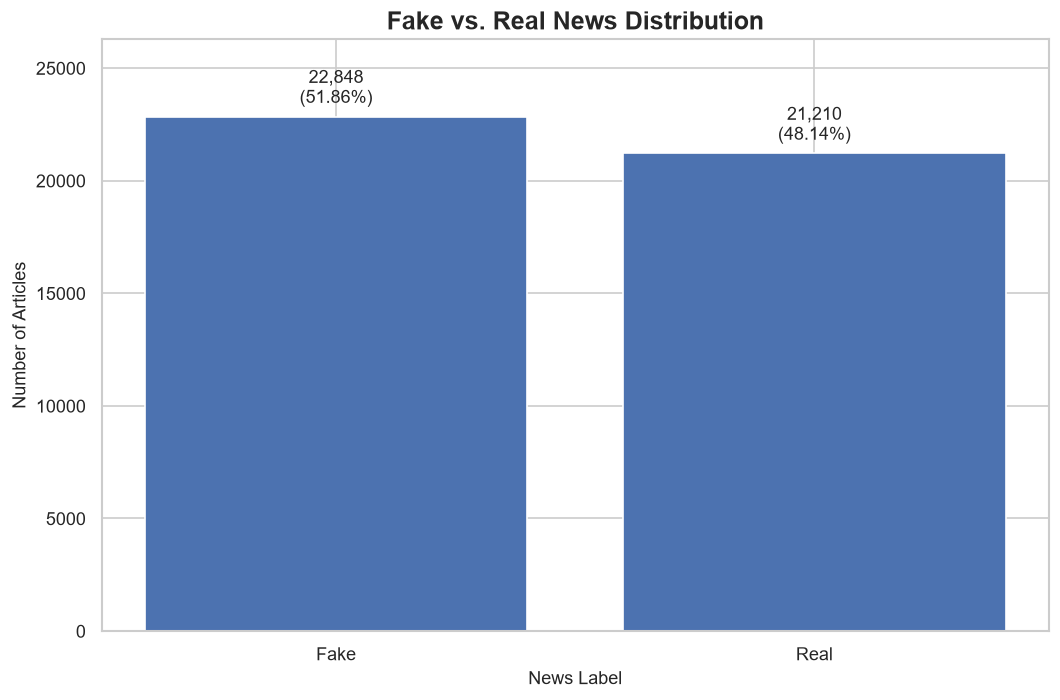

Saved: C:\Users\mi\Desktop\Fake-news detection\results\figures\13_cleaned_class_distribution.png
Saved: C:\Users\mi\Desktop\Fake-news detection\results\tables\cleaned_class_distribution.csv


In [21]:

import pandas as pd
import matplotlib.pyplot as plt

# Count cleaned records in each class
class_counts = (
    df_clean["label"]
    .map({0: "Fake", 1: "Real"})
    .value_counts()
    .reindex(["Fake", "Real"], fill_value=0)
)

class_percentages = class_counts / class_counts.sum() * 100

class_summary = pd.DataFrame({
    "News Label": class_counts.index,
    "Article Count": class_counts.values,
    "Percentage": class_percentages.values.round(2)
})

display(class_summary)

class_summary.to_csv(
    RESULTS_TABLES / "cleaned_class_distribution.csv",
    index=False
)

# Plot count and percentage
fig, ax = plt.subplots(figsize=(9, 6))

bars = ax.bar(
    class_counts.index,
    class_counts.values
)

ax.set_title(
    "Fake vs. Real News Distribution",
    fontsize=15,
    fontweight="bold"
)
ax.set_xlabel("News Label")
ax.set_ylabel("Number of Articles")

for bar, label in zip(bars, class_counts.index):
    count = class_counts[label]
    pct = class_percentages[label]

    ax.annotate(
        f"{count:,}\n({pct:.2f}%)",
        (bar.get_x() + bar.get_width() / 2, bar.get_height()),
        xytext=(0, 5),
        textcoords="offset points",
        ha="center",
        va="bottom",
        fontsize=11
    )

ax.set_ylim(0, class_counts.max() * 1.15)
plt.tight_layout()

output_path = RESULTS_FIGURES / "13_cleaned_class_distribution.png"
plt.savefig(output_path, dpi=300, bbox_inches="tight")
plt.show()

print("Saved:", output_path)
print("Saved:", RESULTS_TABLES / "cleaned_class_distribution.csv")

**Interpretation (class distribution after cleaning).** After cleaning, 22,848 Fake (51.86 %) and 21,210 Real (48.14 %) remain — nearly balanced. Cleaning removed 2.70 % of Fake but only 0.97 % of Real records, so the class ratio moved slightly toward Real.

##  Subject-wise News Label Proportions

This analysis compares the proportion of fake and real articles within each subject category. It helps identify potential dataset construction bias and explains why subject metadata should not be used as a direct predictor in the primary text-classification model.


label_name,Fake,Real
subject,,
Government News,100.0,0.0
Middle-east,100.0,0.0
News,100.0,0.0
US_News,100.0,0.0
left-news,100.0,0.0
politics,100.0,0.0
politicsNews,0.0,100.0
worldnews,0.0,100.0


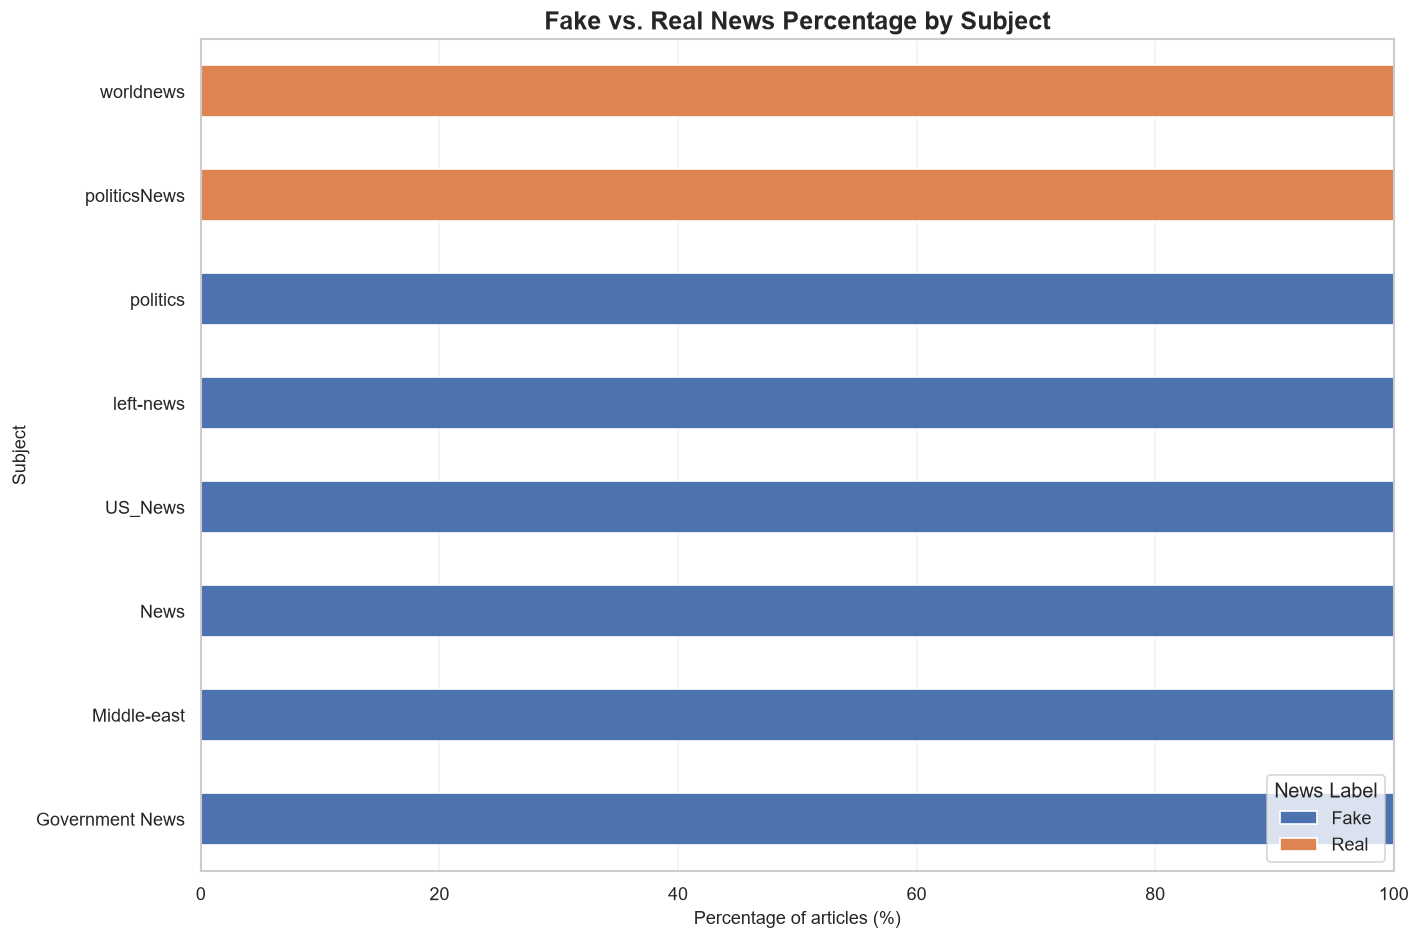

Subject percentage analysis completed.
Saved: C:\Users\mi\Desktop\Fake-news detection\results\figures\14_subject_label_percentages.png
Saved: C:\Users\mi\Desktop\Fake-news detection\results\tables\subject_label_counts.csv
Saved: C:\Users\mi\Desktop\Fake-news detection\results\tables\subject_label_percentages.csv


In [22]:

import pandas as pd
import matplotlib.pyplot as plt

# Build subject-wise counts and percentages
subject_df = df_clean[["subject", "label"]].copy()

subject_df["label_name"] = subject_df["label"].map({
    0: "Fake",
    1: "Real"
})

subject_counts = pd.crosstab(
    subject_df["subject"],
    subject_df["label_name"]
)

# Ensure both columns are present
for col in ["Fake", "Real"]:
    if col not in subject_counts.columns:
        subject_counts[col] = 0

subject_counts = subject_counts[["Fake", "Real"]]

subject_percentages = (
    subject_counts
    .div(subject_counts.sum(axis=1), axis=0)
    .mul(100)
)

# Save the counts and percentages
subject_counts.to_csv(
    RESULTS_TABLES / "subject_label_counts.csv"
)

subject_percentages.round(2).to_csv(
    RESULTS_TABLES / "subject_label_percentages.csv"
)

display(subject_percentages.round(2))

# Plot stacked percentage bars
ax = subject_percentages.plot(
    kind="barh",
    stacked=True,
    figsize=(12, 8),
    xlim=(0, 100)
)

ax.set_title(
    "Fake vs. Real News Percentage by Subject",
    fontsize=15,
    fontweight="bold"
)
ax.set_xlabel("Percentage of articles (%)")
ax.set_ylabel("Subject")
ax.legend(title="News Label", loc="lower right")
ax.grid(axis="x", alpha=0.25)

plt.tight_layout()

output_path = RESULTS_FIGURES / "14_subject_label_percentages.png"
plt.savefig(output_path, dpi=300, bbox_inches="tight")
plt.show()

print("Subject percentage analysis completed.")
print("Saved:", output_path)
print("Saved:", RESULTS_TABLES / "subject_label_counts.csv")
print("Saved:", RESULTS_TABLES / "subject_label_percentages.csv")

**Interpretation (subject proportions).** The 100 %/0 % bars confirm that no subject contains both classes. Hence a *subject-held-out* experiment (Notebook 02, V5) can only hold out one Real and one Fake subject at the same time.

## Train / validation / test split (existing manifest)

The split used by Notebooks 02 and 03 was created once, grouped by normalised title+body pair, and saved as `results/tables/data_split_manifest.csv`. **This notebook does not create a new split.** It loads the saved manifest, recomputes every integrity check from the data (nothing is hard-coded), records SHA-256 hashes so later changes are detectable, and compares the manifest with an in-memory regeneration using the original procedure (70 % / 15 % / 15 %, `GroupShuffleSplit`, seed 42).

In [23]:
from sklearn.model_selection import GroupShuffleSplit

df_clean = df_clean.reset_index(drop=True)
groups = fu.article_key(df_clean["title"], df_clean["text"])   # same key as the original split

MANIFEST_PATH = TABLES_DIR / "data_split_manifest.csv"


def regenerate_original_split(frame, group_keys):
    """In-memory replica of the original procedure (does NOT write anything)."""
    s1 = GroupShuffleSplit(n_splits=1, test_size=0.30, random_state=42)
    train_i, temp_i = next(s1.split(frame, groups=group_keys))
    s2 = GroupShuffleSplit(n_splits=1, test_size=0.50, random_state=42)
    val_rel, test_rel = next(s2.split(frame.iloc[temp_i], groups=group_keys.iloc[temp_i]))
    return train_i, temp_i[val_rel], temp_i[test_rel]


regen_train, regen_val, regen_test = regenerate_original_split(df_clean, groups)

if MANIFEST_PATH.exists():
    manifest = pd.read_csv(MANIFEST_PATH)
    print("Loaded EXISTING split manifest (authoritative):", MANIFEST_PATH.name)
elif ALLOW_MANIFEST_CREATION:
    manifest = pd.DataFrame({
        "row_index": list(regen_train) + list(regen_val) + list(regen_test),
        "partition": ["train"] * len(regen_train) + ["validation"] * len(regen_val)
                     + ["test"] * len(regen_test),
    })
    manifest.to_csv(MANIFEST_PATH, index=False)
    print("Manifest was MISSING and creation was explicitly allowed -> created.")
else:
    raise FileNotFoundError(
        f"{MANIFEST_PATH} is missing. It is the project's authoritative split and is never "
        "regenerated silently. Restore it from backup (preferred) or set the environment "
        "variable FN_ALLOW_MANIFEST_CREATION=1 to create it once with the original procedure."
    )

train_idx = manifest.loc[manifest["partition"] == "train", "row_index"].astype(int).to_numpy()
val_idx = manifest.loc[manifest["partition"] == "validation", "row_index"].astype(int).to_numpy()
test_idx = manifest.loc[manifest["partition"] == "test", "row_index"].astype(int).to_numpy()

# ---- integrity checks, all computed ------------------------------------------------
g_train, g_val, g_test = (set(groups.iloc[i]) for i in (train_idx, val_idx, test_idx))
labels = df_clean["label"]
integrity = pd.DataFrame([
    ("Manifest has the columns row_index, partition", {"row_index", "partition"} <= set(manifest.columns)),
    ("Partition names are train / validation / test",
     set(manifest["partition"]) <= {"train", "validation", "test"}),
    ("Every cleaned row appears exactly once",
     manifest["row_index"].is_unique and set(manifest["row_index"]) == set(range(len(df_clean)))),
    ("No article group in both train and validation", g_train.isdisjoint(g_val)),
    ("No article group in both train and test", g_train.isdisjoint(g_test)),
    ("No article group in both validation and test", g_val.isdisjoint(g_test)),
    ("Both labels present in train", set(labels.iloc[train_idx]) == {0, 1}),
    ("Both labels present in validation", set(labels.iloc[val_idx]) == {0, 1}),
    ("Both labels present in test", set(labels.iloc[test_idx]) == {0, 1}),
], columns=["Check", "Passed"])
display(integrity)
assert integrity["Passed"].all(), "Split manifest integrity check FAILED - do not continue."

same_as_regen = (set(train_idx) == set(regen_train) and set(val_idx) == set(regen_val)
                 and set(test_idx) == set(regen_test))
print("Manifest identical to in-memory regeneration with the original procedure:", same_as_regen)
if not same_as_regen:
    print("  -> The manifest remains authoritative (the library version may differ). Nothing was changed.")

# ---- hashes: detect silent changes to the protected files ----------------------------
registry = fu.HashRegistry(TABLES_DIR / "phase1_hash_registry.json", PROJECT_ROOT)
print("Manifest hash:", registry.check(MANIFEST_PATH))
print("Clean CSV hash:", registry.check(DATA_DIR / "combined_fake_news_clean.csv"))

# ---- summaries (protected writes: never replace the existing files) -------------------
part_lookup = {"Train": train_idx, "Validation": val_idx, "Test": test_idx}
split_summary = pd.DataFrame([
    {"Partition": name, "Records": len(idx),
     "Percentage": round(len(idx) / len(df_clean) * 100, 2),
     "Fake": int((labels.iloc[idx] == 0).sum()), "Real": int((labels.iloc[idx] == 1).sum())}
    for name, idx in part_lookup.items()
])
display(split_summary)

class_distribution = pd.DataFrame({
    "partition": ["test", "train", "validation"],
    "Fake": [int((labels.iloc[i] == 0).sum()) for i in (test_idx, train_idx, val_idx)],
    "Real": [int((labels.iloc[i] == 1).sum()) for i in (test_idx, train_idx, val_idx)],
})
print("data_split_summary.csv:", fu.write_protected_csv(split_summary, TABLES_DIR / "data_split_summary.csv"))
print("class_distribution_by_split.csv:",
      fu.write_protected_csv(class_distribution, TABLES_DIR / "class_distribution_by_split.csv"))

train_df = df_clean.iloc[train_idx].copy()
val_df = df_clean.iloc[val_idx].copy()
test_df = df_clean.iloc[test_idx].copy()
partition_of_row = pd.Series(index=range(len(df_clean)), dtype=object)
partition_of_row.loc[manifest["row_index"].astype(int).to_numpy()] = manifest["partition"].to_numpy()

Loaded EXISTING split manifest (authoritative): data_split_manifest.csv


,Check,Passed
0,"Manifest has the columns row_index, partition",True
1,Partition names are train / validation / test,True
2,Every cleaned row appears exactly once,True
3,No article group in both train and validation,True
4,No article group in both train and test,True
5,No article group in both validation and test,True
6,Both labels present in train,True
7,Both labels present in validation,True
8,Both labels present in test,True


Manifest identical to in-memory regeneration with the original procedure: True
Manifest hash: verified
Clean CSV hash: verified


,Partition,Records,Percentage,Fake,Real
0,Train,30796,69.9,15906,14890
1,Validation,6652,15.1,3523,3129
2,Test,6610,15.0,3419,3191


data_split_summary.csv: identical (not rewritten)
class_distribution_by_split.csv: identical (not rewritten)


**Interpretation (split integrity).** The saved manifest passed every computed check: each cleaned record occurs exactly once, no identical title+body group appears in two partitions, and both classes are present in every partition. The class balance is similar across partitions (train 15,906 Fake / 14,890 Real; validation 3,523 / 3,129; test 3,419 / 3,191). The in-memory regeneration check compares the manifest with a replay of the original procedure; if it differs, **the manifest stays authoritative**.

### Duplicate groups and near-duplicates across partitions
The group-aware split only prevents *identical* title+body pairs from crossing partitions. This section measures what it does **not** prevent:

* identical **bodies** or identical **titles** that cross partitions (L3/L4 above), and
* **near-duplicates**: for every validation/test article, the highest TF-IDF cosine similarity to any *training* article (vectoriser fitted on training text only; no labels or model predictions are involved).

It also saves `results/tables/split_group_info.csv` (`group_id`, `group_size`, `first_in_group`, `near_dup_max_sim`) so Notebooks 02 and 03 can report metrics on a **de-duplicated** and a **near-duplicate-free** view of the evaluation data.

In [24]:
from sklearn.feature_extraction.text import TfidfVectorizer

GROUP_INFO_PATH = TABLES_DIR / "split_group_info.csv"

group_info = pd.DataFrame({
    "row_index": np.arange(len(df_clean)),
    "partition": partition_of_row.to_numpy(),
    "label": df_clean["label"].to_numpy(),
    "group_id": fu.group_ids(groups).to_numpy(),
})
group_info["group_size"] = group_info.groupby("group_id")["row_index"].transform("size")
# Groups never cross partitions (checked above), so the first row of a group is
# also the first row of that group inside its own partition.
group_info["first_in_group"] = ~group_info.duplicated("group_id")


def max_cosine_to_reference(Xq, Xref, chunk=300):
    out = np.zeros(Xq.shape[0], dtype=np.float32)
    for start in range(0, Xq.shape[0], chunk):
        sim = Xq[start:start + chunk] @ Xref.T
        out[start:start + chunk] = sim.max(axis=1).toarray().ravel()
    return out


reuse = False
if GROUP_INFO_PATH.exists() and not RECOMPUTE_NEAR_DUPLICATES:
    prev = pd.read_csv(GROUP_INFO_PATH)
    if len(prev) == len(group_info) and (prev["row_index"].to_numpy() == group_info["row_index"].to_numpy()).all():
        group_info["near_dup_max_sim"] = prev["near_dup_max_sim"].to_numpy()
        reuse = True
        print("Re-used near-duplicate scores from the saved file (set RECOMPUTE_NEAR_DUPLICATES=True to redo).")

if not reuse:
    vec = TfidfVectorizer(lowercase=True, stop_words="english", min_df=2, max_df=0.5,
                          sublinear_tf=True, max_features=50_000, dtype=np.float32)
    X_ref = vec.fit_transform(train_df["text"].astype(str))          # training text only
    near = np.full(len(df_clean), np.nan, dtype=np.float32)
    for idx in (val_idx, test_idx):
        near[idx] = max_cosine_to_reference(vec.transform(df_clean["text"].iloc[idx].astype(str)), X_ref)
    group_info["near_dup_max_sim"] = near
    group_info.to_csv(GROUP_INFO_PATH, index=False)
    print("Near-duplicate scan finished and saved.")

# --- partial-overlap leakage the original grouping did not cover (L3 / L4) ----------
tmp = pd.DataFrame({
    "partition": partition_of_row.to_numpy(),
    "body_norm": df_clean["text"].fillna("").astype(str).str.strip().str.lower().to_numpy(),
    "title_norm": df_clean["title"].fillna("").astype(str).str.strip().str.lower().to_numpy(),
})
body_cross = tmp.groupby("body_norm")["partition"].nunique()
title_cross = tmp.groupby("title_norm")["partition"].nunique()
cross_table = pd.DataFrame({
    "check": ["Identical bodies that appear in more than one partition",
              "Identical titles that appear in more than one partition"],
    "groups_crossing_partitions": [int((body_cross > 1).sum()), int((title_cross > 1).sum())],
})
display(cross_table)

# --- near-duplicate summary --------------------------------------------------------
rows = []
for part in ("validation", "test"):
    sub = group_info[group_info["partition"] == part]
    for cls_id, cls_name in ((0, "Fake"), (1, "Real")):
        s = sub.loc[sub["label"] == cls_id, "near_dup_max_sim"]
        rows.append({"partition": part, "class": cls_name, "articles": len(s),
                     "sim>=0.99": int((s >= 0.99).sum()), "sim>=0.95": int((s >= 0.95).sum()),
                     "sim>=0.90": int((s >= 0.90).sum()), "sim>=0.80": int((s >= 0.80).sum()),
                     "median_max_sim": round(float(s.median()), 3)})
near_dup_summary = pd.DataFrame(rows)
display(near_dup_summary)

within_rows = []
for part in ("train", "validation", "test"):
    sub = group_info[group_info["partition"] == part]
    within_rows.append({"partition": part, "records": len(sub), "unique_groups": sub["group_id"].nunique(),
                        "records_in_repeated_groups": int((sub["group_size"] > 1).sum())})
within_summary = pd.DataFrame(within_rows)
display(within_summary)

cross_table.to_csv(TABLES_DIR / "partial_overlap_cross_partition.csv", index=False)
near_dup_summary.to_csv(TABLES_DIR / "near_duplicate_summary.csv", index=False)
within_summary.to_csv(TABLES_DIR / "repeated_groups_by_partition.csv", index=False)

n_eval = int(group_info["partition"].isin(["validation", "test"]).sum())
n_close = int((group_info["near_dup_max_sim"] >= 0.90).sum())
print(f"\n{n_close} of {n_eval} validation/test articles ({n_close / max(n_eval, 1):.1%}) have a training "
      "article with cosine similarity >= 0.90.")
print("Notebooks 02/03 report validation (and, once, test) metrics on the full set, on the de-duplicated "
      "view, and on the near-duplicate-free view (similarity < 0.90).")

Re-used near-duplicate scores from the saved file (set RECOMPUTE_NEAR_DUPLICATES=True to redo).


,check,groups_crossing_partitions
0,Identical bodies that appear in more than one ...,10
1,Identical titles that appear in more than one ...,176


,partition,class,articles,sim>=0.99,sim>=0.95,sim>=0.90,sim>=0.80,median_max_sim
0,validation,Fake,3523,19,40,57,92,0.231
1,validation,Real,3129,69,80,89,101,0.389
2,test,Fake,3419,27,40,68,98,0.235
3,test,Real,3191,64,71,80,107,0.387


,partition,records,unique_groups,records_in_repeated_groups
0,train,30796,27059,7155
1,validation,6652,5798,1642
2,test,6610,5799,1548



294 of 13262 validation/test articles (2.2%) have a training article with cosine similarity >= 0.90.
Notebooks 02/03 report validation (and, once, test) metrics on the full set, on the de-duplicated view, and on the near-duplicate-free view (similarity < 0.90).


**Interpretation (partial overlap and near-duplicates).** The pair-level grouping prevented identical title+body pairs from crossing partitions but **not** every kind of overlap: 10 identical bodies and 176 identical headlines occur in more than one partition. Using TF-IDF cosine similarity against the training set, **294 of 13262 validation/test articles (2.2%) have a training article with similarity ≥ 0.90** (mostly Real: 89 validation and 80 test Real articles vs 57 and 68 Fake). This is a small share, so duplicates are unlikely to explain the high scores — Notebook 02 confirms this by scoring a *de-duplicated* and a *near-duplicate-free* view — but they are reported as a limitation, not ignored.

## Publisher markers and formatting shortcuts
Real articles come from one publisher and Fake articles from many, so a classifier can score highly by recognising *where text came from* rather than *what it says*. This section looks for such shortcuts **in the training partition only**, from the actual data:

1. what articles look like at their opening,
2. how well simple formatting numbers (headline/body length) separate the classes on their own (univariate ROC-AUC; 0.5 = no information),
3. how often each *candidate* marker pattern occurs per class. The candidate patterns live in `src/fakenews_utils.py`; they are hypotheses, and a pattern is only used downstream if the training prevalence shows a strong class skew.

In [25]:
from collections import Counter
import re
from sklearn.metrics import roc_auc_score

y_train_nb1 = train_df["label"].to_numpy()

# 1) Inspect actual openings (seeded sample, training partition only)
print("Opening 110 characters of 8 random TRAINING articles per class:\n")
for cls_id, cls_name in ((0, "Fake"), (1, "Real")):
    print(f"--- {cls_name} ---")
    sample = train_df[train_df["label"] == cls_id].sample(8, random_state=RANDOM_STATE)
    for t in sample["text"].astype(str):
        print("  ", t[:110].replace("\n", " "))

# 2) Most frequent opening three-token patterns per class
tok = re.compile(r"\w+|[^\w\s]")
def opening(text, n=3):
    return " ".join(tok.findall(text[:80].lower())[:n])
rows = []
for cls_id, cls_name in ((0, "Fake"), (1, "Real")):
    sub = train_df[train_df["label"] == cls_id]["text"].astype(str)
    c = Counter(opening(t) for t in sub)
    for pattern, n in c.most_common(10):
        rows.append({"class": cls_name, "opening_3_tokens": pattern, "articles": n,
                     "share_of_class_pct": round(100 * n / len(sub), 2)})
opening_table = pd.DataFrame(rows)
print("\nMost frequent opening patterns:")
display(opening_table)

# 3) Univariate shortcut strength: ROC-AUC of single formatting numbers
feat = pd.DataFrame({
    "title_words": train_df["title"].fillna("").astype(str).str.split().str.len(),
    "title_chars": train_df["title"].fillna("").astype(str).str.len(),
    "body_words": train_df["text"].astype(str).str.split().str.len(),
    "body_chars": train_df["text"].astype(str).str.len(),
})
auc_rows = []
for col in feat.columns:
    auc = roc_auc_score(y_train_nb1, feat[col])
    auc_rows.append({"feature": col, "roc_auc_for_Real": round(auc, 4),
                     "separation_|2*AUC-1|": round(abs(2 * auc - 1), 4)})
univariate_auc = pd.DataFrame(auc_rows)
print("\nUnivariate ROC-AUC of formatting numbers (training partition):")
display(univariate_auc)

# 4) Candidate marker prevalence per class (training partition only)
rule_report_nb1 = fu.compute_rule_report(train_df["title"], train_df["text"], y_train_nb1)
display(rule_report_nb1.sort_values("skew_ratio", ascending=False).round(4))

opening_table.to_csv(TABLES_DIR / "opening_patterns_by_class.csv", index=False)
univariate_auc.to_csv(TABLES_DIR / "univariate_formatting_auc_train.csv", index=False)
rule_report_nb1.to_csv(TABLES_DIR / "marker_rule_prevalence_train.csv", index=False)

sel = rule_report_nb1[rule_report_nb1["selected"]]
print("\nCandidate markers that pass the pre-set criterion on TRAINING data "
      "(>=1% of one class AND >=5x skew between classes):")
print(", ".join(sel["rule"]) if len(sel) else "(none)")

Opening 110 characters of 8 random TRAINING articles per class:

--- Fake ---
   Bob Schieffer is an old-school newsman. There s no doubt that the former Face the Nationhost leans left, but h
   The only possible explanation for this embarrassing misstep is that either Obama s speechwriter isn t very fon
   The wu$$ification of our military Army ROTC cadets are complaining on message boards that they were pressured 
   President Obama had scathing words for the lawmakers who voted to overturn his presidential veto on a bill tha
   Soros is a Hungarian immigrant who s doing his best to turn America into a weak third world failed country. He
   Don t mess with NASA because they will burn you.When a climate change denier made a comment on a post made by 
   Leading Republican presidential candidate Donald Trump has been bashing party leaders for several days after r
   During a campaign event at Iowa s Wesleyan University, Bernie Sanders spoke to the audience about how Walmart 
--- Real -

,class,opening_3_tokens,articles,share_of_class_pct
0,Fake,21st century wire,507,3.19
1,Fake,donald trump s,161,1.01
2,Fake,donald trump is,150,0.94
3,Fake,donald trump has,125,0.79
4,Fake,tune in to,124,0.78
5,Fake,https : /,69,0.43
6,Fake,this is a,58,0.36
7,Fake,it s no,49,0.31
8,Fake,if there s,44,0.28
9,Fake,one of the,44,0.28



Univariate ROC-AUC of formatting numbers (training partition):


,feature,roc_auc_for_Real,separation_|2*AUC-1|
0,title_words,0.1258,0.7485
1,title_chars,0.1151,0.7698
2,body_words,0.4673,0.0654
3,body_chars,0.4813,0.0374


,rule,description,prevalence_fake,prevalence_real,skew_ratio,selected
0,dateline_reuters,Leading '[CITY] (Reuters) -' dateline (seen in...,0.0001,0.9842,875.1146,True
4,featured_image,'Featured image (via ...)' caption phrase,0.3392,0.0000,340.1802,True
5,image_credit,'Photo/Image via|credit' caption phrase,0.2852,0.0000,286.2383,True
6,getty_images,'Getty Images' credit,0.1705,0.0000,171.5017,True
7,pic_twitter,Embedded tweet picture link,0.1503,0.0000,151.3206,True
1,reuters_token,Any remaining 'Reuters' token,0.0133,0.9984,69.7492,True
10,watch_label,'WATCH:' embed label,0.0594,0.0000,60.4115,True
3,century_wire,'21st Century Wire (says)' (seen in a Fake sam...,0.0541,0.0000,55.0676,True
8,url,URLs,0.1453,0.0020,48.5247,True
11,read_more_label,'READ MORE:' label,0.0320,0.0004,23.5221,True



Candidate markers that pass the pre-set criterion on TRAINING data (>=1% of one class AND >=5x skew between classes):
dateline_reuters, reuters_token, reporting_by_credit, century_wire, featured_image, image_credit, getty_images, pic_twitter, url, twitter_handle, watch_label, read_more_label


**Interpretation (marker analysis — verification-run findings).** Using the training partition only:

* **Dateline.** A leading "`CITY (Reuters) -`" dateline occurs in **98.4%** of Real articles and **0.01%** of Fake articles; the token `reuters` occurs in 99.8% of Real and 1.3% of Fake. The three most common Real openings are all datelines (e.g. 30.3 % of Real articles begin "washington ( reuters").
* **Fake-side page furniture.** `featured image` (33.9% of Fake), image/photo credits (28.5%), Getty credits (17.1%), embedded tweets `pic.twitter.com` (15.0%), @handles (26.7%), URLs (14.5%), "WATCH:" (5.9%) and "21st Century Wire" (5.4%; 3.2 % of Fake articles *open* with it).
* **Headline length** is the strongest single formatting number (AUC 0.126); body length is not (AUC 0.467).
* The generic "`CITY -`" dateline is *not* class-skewed and is therefore not used as a rule.

**Meaning.** A classifier could reach high accuracy by recognising the Reuters dateline or Fake page furniture without reading the news. This is a hypothesis about *capability*, not a measurement of what any trained model actually uses — that is tested by the ablations in Notebook 02.

## Summary of verified findings and implications

**Verified in this notebook (computed from the files):**
* Labels follow Fake.csv → 0 and True.csv → 1 with no mismatches; the cleaned CSV reproduces exactly.
* 44,898 raw records → 44,058 after removing 631 empty-text records (630 Fake) and 209 exact duplicates (206 Real).
* 4,943 repeated title+body pairs remain, without label conflicts; they are grouped in the split.
* Every subject is single-class; dates before 2016 are Fake-only; headline length strongly separates the classes; bodies under 20 words are Fake-only.
* Real articles carry a Reuters dateline in 98.4% of cases; Fake articles carry web/social page furniture.
* The saved split is internally consistent; 2.2% of validation/test articles have a ≥ 0.90 near-duplicate in training; 10 bodies and 176 headlines cross partitions.

**Data-quality concerns.** Source confounding (one publisher for all Real articles); collection-process artefacts (empty/short bodies, page furniture); narrow US-politics domain and period; residual near-duplicates.

**Implications for later notebooks.**
1. `subject` and `date` stay out of every model.
2. Notebook 02 must compare raw, body-only, title-only and **marker-stripped** inputs, and report de-duplicated and near-duplicate-free views.
3. Headline-only or very short input is out of scope for deployment.
4. All results are labelled *in-distribution on a source-confounded dataset*; none verifies facts.

**Not established here.** That any of these shortcuts is *used* by a model (tested in Notebook 02/05), that the labels are factually correct, or that results transfer to other publishers.

### References
* Ahmed, H., Traore, I., & Saad, S. (2017). *Detection of Online Fake News Using N-Gram Analysis and Machine Learning Techniques.* Lecture Notes in Computer Science, 127–138. https://doi.org/10.1007/978-3-319-69155-8_9
* Ahmed, H., Traore, I., & Saad, S. (2018). *Detecting opinion spams and fake news using text classification.* Security and Privacy, 1(1). https://doi.org/10.1002/spy2.9
* arXiv:2305.19194, *FakeSwarm: Improving Fake News Detection with Swarming Characteristics* (reports the Reuters-dateline shortcut in this dataset).

In [26]:
required_files = [
    DATA_DIR / "combined_fake_news_clean.csv",
    TABLES_DIR / "dataset_quality_report.csv",
    TABLES_DIR / "data_split_summary.csv",
    TABLES_DIR / "data_split_manifest.csv",
    TABLES_DIR / "class_distribution_by_split.csv",
    TABLES_DIR / "label_assignment_verification.csv",
    TABLES_DIR / "exclusions_by_class.csv",
    TABLES_DIR / "duplicate_taxonomy.csv",
    TABLES_DIR / "split_group_info.csv",
    TABLES_DIR / "marker_rule_prevalence_train.csv",
    TABLES_DIR / "phase1_hash_registry.json",
]

for file in required_files:
    print(f"{'OK     ' if file.exists() else 'MISSING'} {file.name}")

assert all(file.exists() for file in required_files), (
    "Some required files are missing. Check the paths above."
)
print("\nNotebook 01 outputs verified.")

OK      combined_fake_news_clean.csv
OK      dataset_quality_report.csv
OK      data_split_summary.csv
OK      data_split_manifest.csv
OK      class_distribution_by_split.csv
OK      label_assignment_verification.csv
OK      exclusions_by_class.csv
OK      duplicate_taxonomy.csv
OK      split_group_info.csv
OK      marker_rule_prevalence_train.csv
OK      phase1_hash_registry.json

Notebook 01 outputs verified.


## Limitations to state in the project report
1. **Label = dataset label, not truth.** No claim is verified against facts.
2. **Source confounding.** All Real articles come from a single publisher; Fake articles come from many. Models may learn publisher style rather than veracity.
3. **Narrow domain and period.** The data is dominated by US political news from a limited period.
4. **Residual duplication.** Exact duplicates were removed and repeated pairs grouped, but near-duplicates and same-body/same-title cases can still cross partitions; their extent is measured above.
5. **Title-only records were excluded**, so headline-only input is out of scope.